# Tinkoff Media Analytics
Исследование YouTube-контента об Олеге Тинькове: граф запросов, сбор метаданных, тональность комментариев и аналитические признаки.

Это опубликованная исследовательская версия: сохранены исходная последовательность, итерационные исправления и итоговые агрегированные графики. Исходный файл выполнялся не по порядку; **Run All с чистого kernel пока не подтверждён**. Сначала изучите README и настройки CONFIG. Полный сбор из сети при публикации не выполнялся.

CTR, показы и охват представлены сценарными оценками; реальные показы и CTR из YouTube Analytics не получены. Сырые комментарии, журналы сбора и служебные widget-данные в публикацию не включены. Google Drive подключается только при USE_GOOGLE_DRIVE=True.

In [ ]:
# =========================================================
# CELL 1. INSTALL
# =========================================================
%pip install -q yt-dlp transformers torch pandas numpy requests tqdm python-dateutil scikit-learn matplotlib seaborn networkx

In [ ]:
# =========================================================
# CELL 2. IMPORTS
# =========================================================
import os
import re
import json
import math
import time
import random
import hashlib
import warnings
import requests
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from collections import deque, Counter
from datetime import datetime, timezone
from dateutil import parser as dt_parser

import yt_dlp
import torch
from transformers import pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 200)

In [ ]:
# =========================================================
# CELL 3. CONFIG
# =========================================================
CONFIG = {
    # -----------------------------
    # Query setup
    # -----------------------------
    "seed_queries": [
        "Олег Тиньков",
        "Тиньков интервью",
        "Тиньков подкаст",
        "Олег Тиньков Собчак",
        "Олег Тиньков Дудь"
    ],
    "start_keyword": "Олег Тиньков",
    "query_suggest_limit_graph": 3,
    "query_suggest_limit_search": 5,
    "bfs_depth": 2,
    "dfs_depth": 3,

    # -----------------------------
    # Search scope
    # -----------------------------
    "search_limit_per_query": 15,
    "max_enrich_videos": 40,
    "max_comments_per_video": 150,
    "channel_snapshot_limit": 40,

    # -----------------------------
    # Filters
    # -----------------------------
    "min_views_threshold": 0,
    "min_duration_seconds": 0,
    "max_duration_seconds": 4 * 60 * 60,
    "language_priority": ["ru", "en"],

    # -----------------------------
    # Requests / pacing
    # -----------------------------
    "request_sleep_min": 0.4,
    "request_sleep_max": 1.0,
    "requests_timeout": 20,

    # -----------------------------
    # Proxy assumptions
    # -----------------------------
    "assumed_ctr_values": [0.02, 0.04, 0.06],
    "assumed_frequency_values": [1.2, 1.5, 2.0],
    "rank_ctr_priors": {
        1: 0.12, 2: 0.08, 3: 0.06, 4: 0.05, 5: 0.04,
        6: 0.035, 7: 0.03, 8: 0.025, 9: 0.02, 10: 0.018,
        11: 0.016, 12: 0.014, 13: 0.012, 14: 0.011, 15: 0.01
    },

    # -----------------------------
    # Output
    # -----------------------------
    "out_dir": "media_analytics_output",
    "run_name": f"run_{datetime.now().strftime('%Y%m%d_%H%M%S')}",

    # -----------------------------
    # Models
    # -----------------------------
    "sentiment_model": "blanchefort/rubert-base-cased-sentiment",
}

RUN_DIR = os.path.join(CONFIG["out_dir"], CONFIG["run_name"])
os.makedirs(RUN_DIR, exist_ok=True)

PATHS = {
    "query_graph": os.path.join(RUN_DIR, "query_graph.csv"),
    "videos_raw": os.path.join(RUN_DIR, "videos_raw.csv"),
    "videos_master": os.path.join(RUN_DIR, "videos_master.csv"),
    "comments_raw": os.path.join(RUN_DIR, "comments_raw.csv"),
    "comment_summary": os.path.join(RUN_DIR, "comment_summary_by_video.csv"),
    "channel_snapshots": os.path.join(RUN_DIR, "channel_snapshots.csv"),
    "run_log": os.path.join(RUN_DIR, "run_log.json"),
}

In [ ]:
# =========================================================
# CELL 4. HELPERS (RESTORED & UPDATED)
# =========================================================
import re
import hashlib
import numpy as np
import pandas as pd
import time
import random
from datetime import datetime, timezone

def now_utc_iso():
    return datetime.now(timezone.utc).isoformat()

def safe_sleep():
    time.sleep(random.uniform(CONFIG.get("request_sleep_min", 0.4), CONFIG.get("request_sleep_max", 1.0)))

def clean_text(x):
    if x is None: return ""
    x = str(x)
    x = re.sub(r"\s+", " ", x).strip()
    return x

def count_words(text):
    text = clean_text(text)
    if not text: return 0
    return len(text.split())

def normalize_lang(text):
    text = clean_text(text).lower()
    if re.search(r"[а-яё]", text): return "ru"
    if re.search(r"[a-z]", text): return "en"
    return "unknown"

def has_emoji(text):
    """Простая проверка на наличие эмодзи (символы вне BMP)"""
    if not text: return 0
    return int(any(ord(char) > 0xffff for char in text))

def safe_div(a, b):
    try:
        if b in [0, None] or pd.isna(b): return np.nan
        return a / b
    except: return np.nan

def seconds_to_hms(seconds):
    if seconds is None or pd.isna(seconds): return None
    try:
        seconds = int(seconds)
        h = seconds // 3600
        m = (seconds % 3600) // 60
        s = seconds % 60
        return f"{h}:{m:02d}:{s:02d}" if h > 0 else f"{m}:{s:02d}"
    except: return None

def first_non_null(*vals):
    for v in vals:
        if v is not None and not pd.isna(v) and v != "": return v
    return None

print("Helpers (CELL 4) fully restored and has_emoji added.")

In [ ]:
# =========================================================
# CELL 5. QUERY EXPANSION
# =========================================================
def get_related_queries(base_query, limit=5):
    url = "https://suggestqueries.google.com/complete/search"
    params = {"client": "firefox", "ds": "yt", "q": base_query}
    try:
        r = requests.get(url, params=params, timeout=CONFIG["requests_timeout"])
        r.raise_for_status()
        data = json.loads(r.text)
        suggestions = data[1] if isinstance(data, list) and len(data) > 1 else []
        safe_sleep()
        return suggestions[:limit]
    except Exception as e:
        print(f"Suggest error for '{base_query}': {e}")
        return []

def run_bfs(start_node, max_depth=2, branch_limit=3):
    visited = set()
    queue = deque([(start_node, 0)])
    edges = []

    while queue:
        current_node, depth = queue.popleft()
        if current_node in visited or depth > max_depth:
            continue
        visited.add(current_node)

        if depth < max_depth:
            neighbors = get_related_queries(current_node, limit=branch_limit)
            for pos, neighbor in enumerate(neighbors, start=1):
                edges.append({
                    "algo": "BFS",
                    "source_query": current_node,
                    "target_query": neighbor,
                    "depth": depth + 1,
                    "rank_within_source": pos,
                })
                if neighbor not in visited:
                    queue.append((neighbor, depth + 1))
    return edges

def run_dfs(start_node, max_depth=3, branch_limit=3):
    visited = set()
    stack = [(start_node, 0)]
    edges = []

    while stack:
        current_node, depth = stack.pop()
        if current_node in visited or depth > max_depth:
            continue
        visited.add(current_node)

        if depth < max_depth:
            neighbors = get_related_queries(current_node, limit=branch_limit)
            for pos, neighbor in enumerate(reversed(neighbors), start=1):
                edges.append({
                    "algo": "DFS",
                    "source_query": current_node,
                    "target_query": neighbor,
                    "depth": depth + 1,
                    "rank_within_source": pos,
                })
                if neighbor not in visited:
                    stack.append((neighbor, depth + 1))
    return edges

def build_query_graph():
    bfs_edges = run_bfs(
        CONFIG["start_keyword"],
        max_depth=CONFIG["bfs_depth"],
        branch_limit=CONFIG["query_suggest_limit_graph"]
    )
    dfs_edges = run_dfs(
        CONFIG["start_keyword"],
        max_depth=CONFIG["dfs_depth"],
        branch_limit=CONFIG["query_suggest_limit_graph"]
    )

    df_graph = pd.DataFrame(bfs_edges + dfs_edges).drop_duplicates()
    if df_graph.empty:
        all_queries = list(dict.fromkeys(CONFIG["seed_queries"]))
    else:
        all_queries = list(dict.fromkeys(
            CONFIG["seed_queries"] +
            df_graph["source_query"].tolist() +
            df_graph["target_query"].tolist()
        ))

    return df_graph, all_queries

In [ ]:
# =========================================================
# CELL 6. SEARCH VIA YT-DLP
# =========================================================
def yt_search(query, max_results=15):
    search_query = f"ytsearch{max_results}:{query}"
    ydl_opts = {
        "quiet": True,
        "skip_download": True,
        "extract_flat": True,
        "no_warnings": True,
    }

    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            info = ydl.extract_info(search_query, download=False)
        entries = info.get("entries", []) if info else []
        rows = []

        for rank, entry in enumerate(entries, start=1):
            video_id = entry.get("id")
            url = entry.get("url")
            if not url or not str(url).startswith("http"):
                url = f"https://www.youtube.com/watch?v={video_id}"

            rows.append({
                "query_expanded": query,
                "search_rank": rank,
                "video_id": video_id,
                "video_url": url,
                "title": clean_text(entry.get("title")),
                "channel_title": clean_text(first_non_null(entry.get("channel"), entry.get("uploader"))),
                "channel_id": clean_text(first_non_null(entry.get("channel_id"), entry.get("uploader_id"))),
                "duration_sec": entry.get("duration"),
                "duration_hms": seconds_to_hms(entry.get("duration")),
                "view_count_search": entry.get("view_count"),
                "live_status": entry.get("live_status"),
                "availability_search": entry.get("availability"),
                "collected_at": now_utc_iso(),
            })
        safe_sleep()
        return rows
    except Exception as e:
        print(f"Search error for '{query}': {e}")
        return []

def collect_videos(queries):
    rows = []
    for query in tqdm(queries, desc="Searching videos"):
        rows.extend(yt_search(query, CONFIG["search_limit_per_query"]))

    df = pd.DataFrame(rows)
    if df.empty:
        return df

    df["query_seed"] = df["query_expanded"].apply(
        lambda x: next((q for q in CONFIG["seed_queries"] if q.lower() in x.lower() or x.lower() in q.lower()), CONFIG["seed_queries"][0])
    )

    # how often video appears across query set
    presence = (
        df.groupby("video_url", as_index=False)
        .agg(
            query_presence_count=("query_expanded", "nunique"),
            best_rank_across_queries=("search_rank", "min"),
            mean_rank_across_queries=("search_rank", "mean")
        )
    )
    df = df.merge(presence, on="video_url", how="left")

    # keep best row per video, but preserve strongest search visibility
    df = df.sort_values(["video_url", "search_rank"]).drop_duplicates("video_url", keep="first").reset_index(drop=True)

    # basic filters
    df = df[
        (df["duration_sec"].fillna(0) >= CONFIG["min_duration_seconds"]) &
        (df["duration_sec"].fillna(0) <= CONFIG["max_duration_seconds"])
    ].copy()

    return df

In [ ]:
# =========================================================
# CELL 7. VIDEO ENRICHMENT
# =========================================================
def fetch_video_metadata(video_url):
    ydl_opts = {
        "quiet": True,
        "skip_download": True,
        "no_warnings": True,
    }
    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            info = ydl.extract_info(video_url, download=False)

        return {
            "video_url": info.get("webpage_url", video_url),
            "video_id_meta": info.get("id"),
            "title_full": clean_text(info.get("title")),
            "description": clean_text(info.get("description")),
            "tags": info.get("tags"),
            "categories": info.get("categories"),
            "upload_date_raw": info.get("upload_date"),
            "timestamp": info.get("timestamp"),
            "release_timestamp": info.get("release_timestamp"),
            "duration_sec_meta": info.get("duration"),
            "view_count": info.get("view_count"),
            "like_count": info.get("like_count"),
            "comment_count": info.get("comment_count"),
            "channel": clean_text(info.get("channel")),
            "channel_id_meta": clean_text(info.get("channel_id")),
            "uploader": clean_text(info.get("uploader")),
            "uploader_id": clean_text(info.get("uploader_id")),
            "channel_follower_count": info.get("channel_follower_count"),
            "channel_is_verified": info.get("channel_is_verified"),
            "availability": info.get("availability"),
            "language": info.get("language"),
            "playable_in_embed": info.get("playable_in_embed"),
            "age_limit": info.get("age_limit"),
            "thumbnail": info.get("thumbnail"),
            "subtitles_available": int(bool(info.get("subtitles"))),
            "automatic_captions_available": int(bool(info.get("automatic_captions"))),
        }
    except Exception as e:
        print(f"Metadata error for {video_url}: {e}")
        return {"video_url": video_url}

def enrich_videos(df_raw, max_videos=40):
    if df_raw.empty:
        return pd.DataFrame()

    urls = df_raw["video_url"].tolist()[:max_videos]
    meta_rows = []

    for url in tqdm(urls, desc="Enriching videos"):
        meta_rows.append(fetch_video_metadata(url))
        safe_sleep()

    df_meta = pd.DataFrame(meta_rows)
    df = df_raw.merge(df_meta, on="video_url", how="left")

    # unify fields
    df["video_id"] = df["video_id"].fillna(df["video_id_meta"])
    df["channel_id"] = df["channel_id"].replace("", np.nan).fillna(df["channel_id_meta"])
    df["channel_title"] = df["channel_title"].replace("", np.nan).fillna(df["channel"]).fillna(df["uploader"])
    df["duration_sec"] = df["duration_sec"].fillna(df["duration_sec_meta"])
    df["title"] = df["title"].replace("", np.nan).fillna(df["title_full"])

    return df

In [ ]:
# =========================================================
# CELL 8. COMMENTS + SENTIMENT
# =========================================================
device_num = 0 if torch.cuda.is_available() else -1
print("CUDA available:", torch.cuda.is_available())

sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model=CONFIG["sentiment_model"],
    device=device_num
)

SUBSCRIBE_PATTERNS = [
    r"\bподписал", r"\bподписк", r"\bsubscribed\b", r"\bsubscribe\b"
]
WATCH_TO_END_PATTERNS = [
    r"досмотр", r"посмотрел до конца", r"смотрел до конца", r"watched till the end", r"watched to the end"
]
REWATCH_PATTERNS = [
    r"пересмотр", r"rewatch", r"watch again"
]

def detect_phrase(text, patterns):
    text = clean_text(text).lower()
    return int(any(re.search(p, text) for p in patterns))

def fetch_comments(video_url, limit=100):
    ydl_opts = {
        "quiet": True,
        "skip_download": True,
        "no_warnings": True,
        "getcomments": True,
        "writesubtitles": False,
        "writeautomaticsub": False,
    }
    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            info = ydl.extract_info(video_url, download=False)

        comments = info.get("comments", []) or []
        rows = []

        for c in comments[:limit]:
            txt = clean_text(c.get("text"))
            rows.append({
                "video_url": video_url,
                "video_id": info.get("id"),
                "comment_id": clean_text(c.get("id")),
                "parent_comment_id": clean_text(c.get("parent")),
                "is_reply": int(bool(c.get("parent"))),
                "comment_author": clean_text(c.get("author")),
                "comment_text": txt,
                "comment_like_count": c.get("like_count"),
                "comment_published_raw": c.get("timestamp"),
                "comment_language_guess": normalize_lang(txt),
                "comment_len_chars": len(txt),
                "comment_len_words": count_words(txt),
                "comment_has_emoji": has_emoji(txt),
                "comment_has_question": int("?" in txt),
                "comment_has_exclamation": int("!" in txt),
                "mentions_tinkov": int(bool(re.search(r"тиньков|tinkov", txt.lower()))),
                "contains_subscribe_phrase": detect_phrase(txt, SUBSCRIBE_PATTERNS),
                "contains_watched_to_end_phrase": detect_phrase(txt, WATCH_TO_END_PATTERNS),
                "contains_rewatch_phrase": detect_phrase(txt, REWATCH_PATTERNS),
            })
        safe_sleep()
        return pd.DataFrame(rows)
    except Exception as e:
        print(f"Comments error for {video_url}: {e}")
        return pd.DataFrame()

def score_sentiment_batch(texts, batch_size=16):
    results = []
    for i in range(0, len(texts), batch_size):
        chunk = [t[:512] if t else "" for t in texts[i:i+batch_size]]
        try:
            out = sentiment_analyzer(chunk)
            results.extend(out)
        except Exception:
            for _ in chunk:
                results.append({"label": None, "score": np.nan})
    return results

def collect_comments_for_videos(df_videos, max_comments_per_video=150):
    if df_videos.empty:
        return pd.DataFrame()

    all_comments = []
    for url in tqdm(df_videos["video_url"].tolist(), desc="Collecting comments"):
        df_c = fetch_comments(url, limit=max_comments_per_video)
        if not df_c.empty:
            all_comments.append(df_c)

    if not all_comments:
        return pd.DataFrame()

    comments = pd.concat(all_comments, ignore_index=True)
    sentiments = score_sentiment_batch(comments["comment_text"].fillna("").tolist(), batch_size=16)
    comments["sentiment_label"] = [x.get("label") for x in sentiments]
    comments["sentiment_score"] = [x.get("score") for x in sentiments]

    comments["comment_published_at"] = pd.to_datetime(comments["comment_published_raw"], unit="s", utc=True, errors="coerce")
    comments["comment_hour"] = comments["comment_published_at"].dt.hour
    comments["comment_weekday"] = comments["comment_published_at"].dt.day_name()

    return comments

def summarize_comments_by_video(df_comments):
    if df_comments.empty:
        return pd.DataFrame()

    sentiment_pivot = (
        df_comments
        .pivot_table(
            index="video_id",
            columns="sentiment_label",
            values="comment_id",
            aggfunc="count",
            fill_value=0
        )
        .reset_index()
    )
    sentiment_pivot.columns = [str(c).lower() if isinstance(c, str) else c for c in sentiment_pivot.columns]

    agg = (
        df_comments.groupby("video_id", as_index=False)
        .agg(
            comments_collected=("comment_id", "count"),
            replies_collected=("is_reply", "sum"),
            avg_comment_len_words=("comment_len_words", "mean"),
            median_comment_like_count=("comment_like_count", "median"),
            subscribe_intent_proxy_count=("contains_subscribe_phrase", "sum"),
            watched_to_end_proxy_count=("contains_watched_to_end_phrase", "sum"),
            rewatch_proxy_count=("contains_rewatch_phrase", "sum"),
            tinkov_mentions_in_comments=("mentions_tinkov", "sum"),
            comments_with_emoji=("comment_has_emoji", "sum"),
            comments_with_questions=("comment_has_question", "sum"),
            comments_with_exclamations=("comment_has_exclamation", "sum"),
            avg_sentiment_score=("sentiment_score", "mean"),
        )
    )

    out = agg.merge(sentiment_pivot, on="video_id", how="left")
    for col in ["positive", "negative", "neutral"]:
        if col not in out.columns:
            out[col] = 0

    out["sentiment_total_classified"] = out[["positive", "negative", "neutral"]].sum(axis=1)
    out["sentiment_positive_share"] = out["positive"] / out["sentiment_total_classified"].replace(0, np.nan)
    out["sentiment_negative_share"] = out["negative"] / out["sentiment_total_classified"].replace(0, np.nan)
    out["sentiment_neutral_share"] = out["neutral"] / out["sentiment_total_classified"].replace(0, np.nan)
    out["net_sentiment"] = (out["positive"] - out["negative"]) / out["sentiment_total_classified"].replace(0, np.nan)
    out["sentiment_polarization"] = (out["positive"] + out["negative"]) / out["sentiment_total_classified"].replace(0, np.nan)
    out["controversy_index"] = (
        2 * np.minimum(out["sentiment_positive_share"].fillna(0), out["sentiment_negative_share"].fillna(0))
    )

    out["subscribe_intent_proxy_share"] = out["subscribe_intent_proxy_count"] / out["comments_collected"].replace(0, np.nan)
    out["completion_intent_proxy_share"] = out["watched_to_end_proxy_count"] / out["comments_collected"].replace(0, np.nan)
    out["rewatch_intent_proxy_share"] = out["rewatch_proxy_count"] / out["comments_collected"].replace(0, np.nan)

    return out

In [ ]:
# =========================================================
# CELL 9. CHANNEL SNAPSHOTS
# =========================================================
def snapshot_channel_from_video(video_url):
    ydl_opts = {
        "quiet": True,
        "skip_download": True,
        "no_warnings": True,
    }
    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl:
            info = ydl.extract_info(video_url, download=False)

        return {
            "snapshot_at": now_utc_iso(),
            "channel_id": clean_text(info.get("channel_id")),
            "channel_title": clean_text(info.get("channel")),
            "channel_follower_count": info.get("channel_follower_count"),
            "uploader_id": clean_text(info.get("uploader_id")),
            "uploader": clean_text(info.get("uploader")),
            "channel_url": clean_text(first_non_null(info.get("channel_url"), info.get("uploader_url"))),
            "source_video_url": video_url,
        }
    except Exception as e:
        print(f"Channel snapshot error for {video_url}: {e}")
        return None

def collect_channel_snapshots(df_videos, limit=40):
    urls = df_videos["video_url"].tolist()[:limit]
    rows = []
    seen = set()

    for url in tqdm(urls, desc="Channel snapshots"):
        row = snapshot_channel_from_video(url)
        if row is not None:
            key = row["channel_id"] or row["channel_title"]
            if key not in seen:
                rows.append(row)
                seen.add(key)
        safe_sleep()

    return pd.DataFrame(rows)

In [ ]:
CONTENT_TYPE_PATTERNS = {
    "интервью": r"интервью|interview|беседа|разговор|в гостях|дудь|собчак|вписка|шманкевич|авен|эхо москвы|осетинская|шихман|познер|ургант|дождь|tvrain|истрия на миллион|в гостях у|эхо",
    "подкаст": r"подкаст|podcast|стрим|эфир|record|радио",
    "шортс": r"\bshorts\b|шортс|коротко|фрагмент|отрывок",
    "лекция": r"лекция|выступление|speech|talk|конференция|форум|мгу|мифи|бизнес-школа|университет",
    "разбор": r"разбор|обзор|анализ|объясняет|поясняет|мнение|суть|почему|как|что будет",
    "новость": r"новост|news|событи|заявил|сказал|ответил|обращение|срочно",
    "мем/нарезка": r"мем|нарезка|лучшие моменты|прикол|смешно|tinkov_vibe"
}

FRAME_PATTERNS = {
    "бизнес-успех": r"бизнес|предприним|миллиард|успех|стартап|компания|деньги|миллионер|богатый",
    "банк/финансы": r"банк|банков|финанс|тинькофф|tinkoff|инвести|акции|кредит",
    "конфликт/скандал": r"скандал|конфликт|разнес|жестко|разоблач|критик|ссора|драка|суд|спор|абрамович",
    "биография/личность": r"кто такой|биография|история|путь|личная жизнь|семья|рак|лейкемия|здоровье",
    "эмиграция/политконтекст": r"уехал|эмиграц|росси|полит|войн|санкц|украин|путин|кипр|лондон",
    "мотивация/советы": r"совет|мотивац|урок|как стать|мышление|правила|ошибки"
}

def classify_by_patterns(text, pattern_dict, default="прочее"):
    text = clean_text(text).lower()
    for label, pattern in pattern_dict.items():
        if re.search(pattern, text):
            return label
    return default

In [ ]:
# =========================================================
# CELL 11. PIPELINE RUN (FIXED SEQUENCE)
# =========================================================
def print_shape(name, df):
    print(f"{name}: shape={df.shape}")

def save_json(obj, path):
    import json
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)

run_log = {
    "started_at": now_utc_iso(),
    "config": CONFIG,
    "paths": PATHS
}

# 1) Построение графа запросов
df_graph, all_queries = build_query_graph()
df_graph.to_csv(PATHS["query_graph"], index=False)
print_shape("df_graph", df_graph)

# 2) Сбор видео
df_raw = collect_videos(all_queries)
df_raw.to_csv(PATHS["videos_raw"], index=False)
print_shape("df_raw", df_raw)

# 3) Обогащение данных
df_enriched = enrich_videos(df_raw, max_videos=CONFIG["max_enrich_videos"])
print_shape("df_enriched", df_enriched)

# 4) Сбор комментариев
df_comments = collect_comments_for_videos(
    df_enriched,
    max_comments_per_video=CONFIG["max_comments_per_video"]
)
df_comments.to_csv(PATHS["comments_raw"], index=False)
print_shape("df_comments", df_comments)

# 5) Агрегация комментариев
df_comment_summary = summarize_comments_by_video(df_comments)
df_comment_summary.to_csv(PATHS["comment_summary"], index=False)
print_shape("df_comment_summary", df_comment_summary)

# 6) Сборка мастер-таблицы (вызываем после всех определений)
# ВАЖНО: используем только точные данные, без заполнения медианами
df_master = build_master_table(df_enriched, df_comment_summary)

# Применяем классификацию сразу здесь
df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
    lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
)

# Фильтр по просмотрам (если задан в конфиге)
df_master = df_master[df_master["observed_view_count"].fillna(0) >= CONFIG["min_views_threshold"]].copy()

# Сохранение
df_master.to_csv(PATHS["videos_master"], index=False)
print_shape("df_master", df_master)

run_log["finished_at"] = now_utc_iso()
save_json(run_log, PATHS["run_log"])

print("Saved to:", RUN_DIR)
display(df_master.head())

In [ ]:
df_master = build_master_table(df_enriched, df_comment_summary)

df_master = df_master[df_master["observed_view_count"].fillna(0) >= CONFIG["min_views_threshold"]].copy()

print(df_master.shape)
display(df_master.head(10))

In [ ]:
# 1. Инициализация и Фиксы
import numpy as np
import pandas as pd
import re
import time
import random
from datetime import datetime, timezone

# Исправленные математические хелперы
def safe_div(a, b):
    a = np.asarray(a, dtype='float64')
    b = np.asarray(b, dtype='float64')
    return np.divide(a, b, out=np.full_like(a, np.nan), where=(~np.isnan(b)) & (b != 0))

def pct(a, b): return safe_div(a, b) * 100
def per_1000(a, b): return safe_div(a, b) * 1000
def clean_text(x): return re.sub(r'\s+', ' ', str(x or '')).strip()
def count_words(text): return len(clean_text(text).split())
def now_utc_iso(): return datetime.now(timezone.utc).isoformat()

In [ ]:
# 2. Функции генерации признаков
def add_time_features(df):
    df = df.copy()
    df['published_at'] = pd.to_datetime(df['timestamp'], unit='s', utc=True, errors='coerce')
    df['video_age_days'] = (pd.Timestamp.now(tz='UTC') - df['published_at']).dt.total_seconds() / 86400
    df['video_age_days'] = df['video_age_days'].clip(lower=0.01)
    return df

def add_text_features(df):
    df = df.copy()
    df['title_len_chars'] = df['title'].str.len().fillna(0)
    df['description'] = df['description'].fillna('')
    df['description_len_words'] = df['description'].apply(count_words)
    df['has_question_in_title'] = df['title'].str.contains(r'\?').fillna(False).astype(int)
    df['has_hashtags_in_description'] = df['description'].str.contains(r'#').fillna(False).astype(int)
    df['contains_tinkov_in_title'] = df['title'].str.contains(r'тиньков|tinkoff', case=False).fillna(False).astype(int)
    return df

def add_metrics(df):
    df = df.copy()
    df['observed_view_count'] = df['view_count'].fillna(df.get('view_count_search', 0))
    df['engagement_total'] = df['like_count'].fillna(0) + df['comment_count'].fillna(0)
    df['engagement_rate_by_views'] = pct(df['engagement_total'], df['observed_view_count'])
    df['views_per_day'] = safe_div(df['observed_view_count'], df.get('video_age_days', 1))
    return df

In [ ]:
# 3. Главная функция сборки
def build_master_table(df_enriched, df_comment_summary):
    if df_enriched.empty: return pd.DataFrame()
    df = df_enriched.copy()
    df = add_time_features(df)
    df = add_text_features(df)
    df = add_metrics(df)

    if df_comment_summary is not None and not df_comment_summary.empty:
        df = df.merge(df_comment_summary, on='video_id', how='left')

    df['collected_at_master'] = now_utc_iso()
    return df

In [ ]:
# 4. Запуск сборки
try:
    df_master = build_master_table(df_enriched, df_comment_summary)
    print(f"Master table created: {df_master.shape}")
    display(df_master.head())
except NameError as e:
    print(f"Ошибка: Проверьте, что df_enriched и df_comment_summary существуют. {e}")

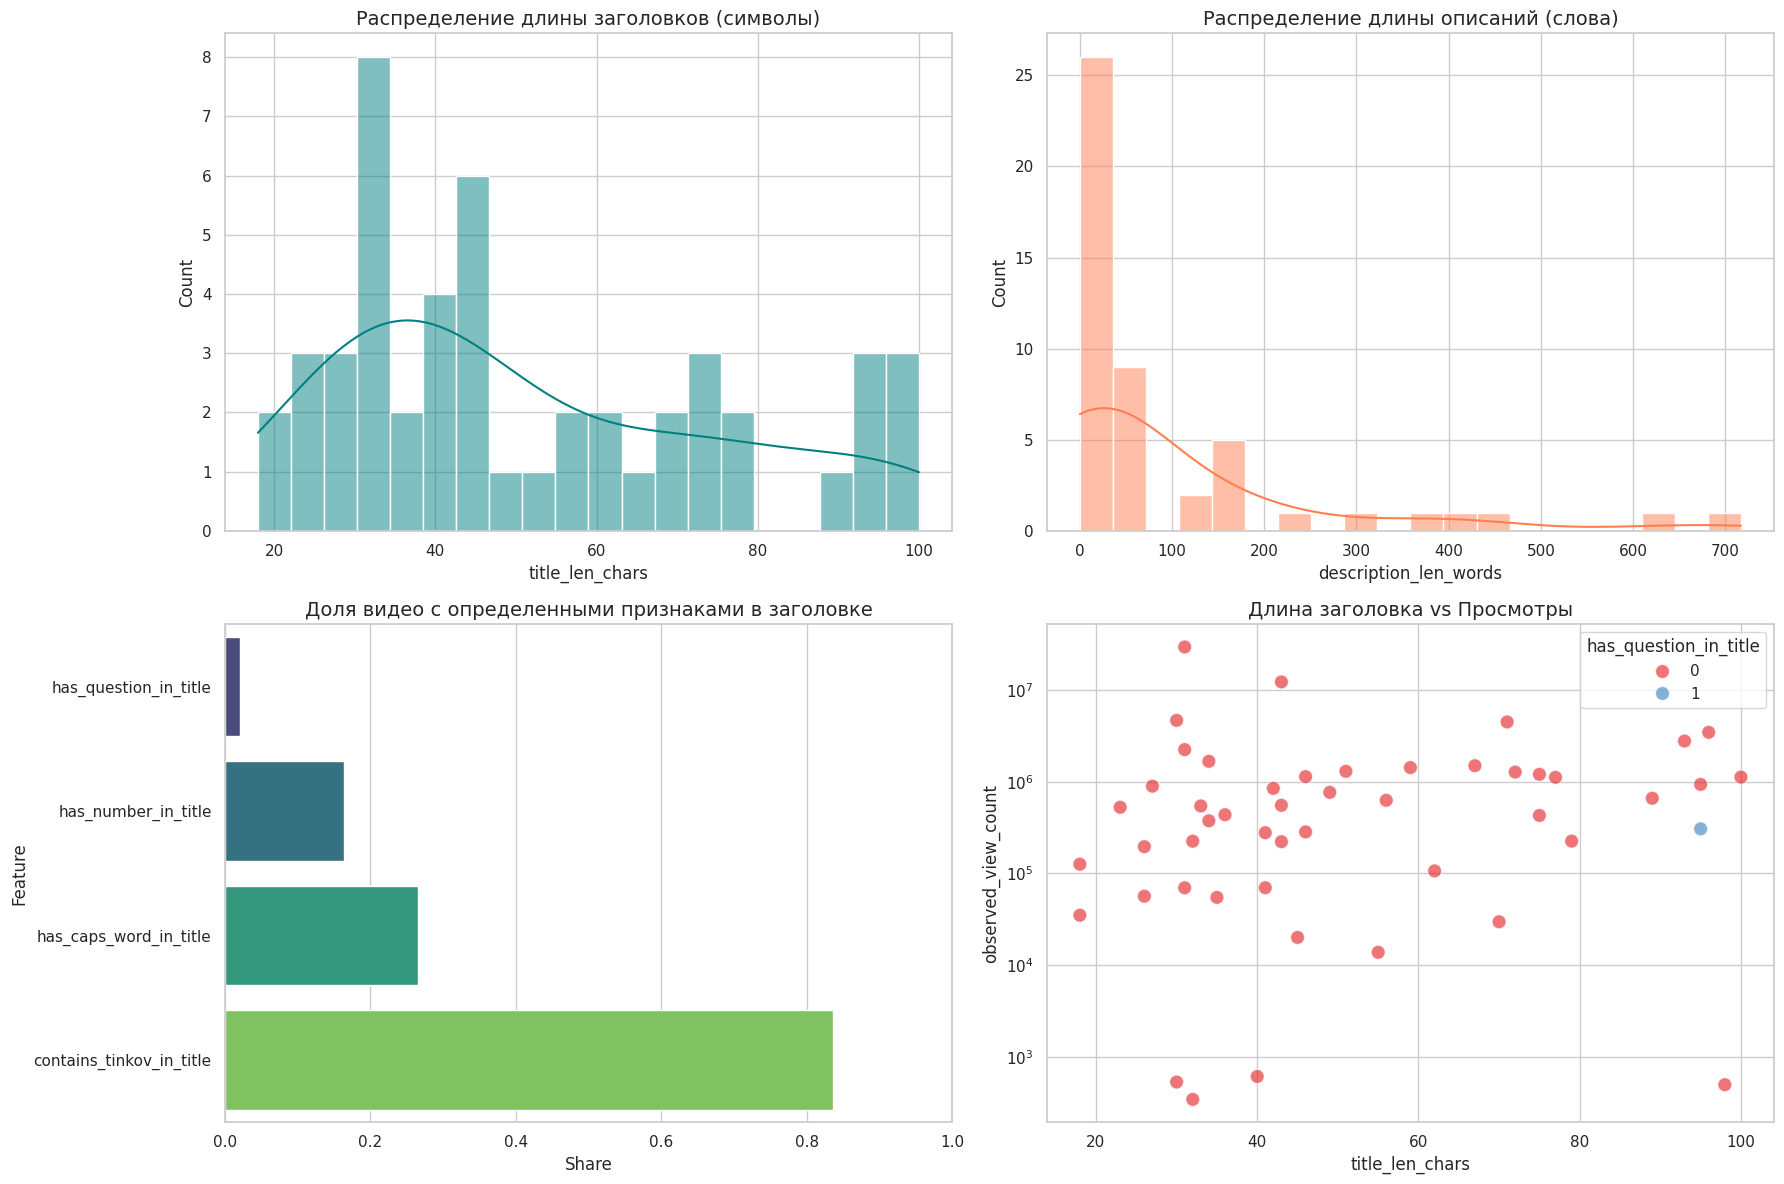

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_master' in globals():
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    # 1. Длина заголовков (в символах)
    sns.histplot(ax=axes[0, 0], data=df_master, x='title_len_chars', kde=True, color='teal', bins=20)
    axes[0, 0].set_title('Распределение длины заголовков (символы)', fontsize=14)

    # 2. Длина описаний (в словах)
    sns.histplot(ax=axes[0, 1], data=df_master, x='description_len_words', kde=True, color='coral', bins=20)
    axes[0, 1].set_title('Распределение длины описаний (слова)', fontsize=14)

    # 3. Наличие элементов в заголовке
    binary_cols = ['has_question_in_title', 'has_number_in_title', 'has_caps_word_in_title', 'contains_tinkov_in_title']
    binary_data = df_master[binary_cols].mean().reset_index()
    binary_data.columns = ['Feature', 'Share']
    sns.barplot(ax=axes[1, 0], data=binary_data, x='Share', y='Feature', palette='viridis')
    axes[1, 0].set_title('Доля видео с определенными признаками в заголовке', fontsize=14)
    axes[1, 0].set_xlim(0, 1)

    # 4. Длина заголовка vs Просмотры
    sns.scatterplot(ax=axes[1, 1], data=df_master, x='title_len_chars', y='observed_view_count', alpha=0.6, hue='has_question_in_title', palette='Set1', s=100)
    axes[1, 1].set_title('Длина заголовка vs Просмотры', fontsize=14)
    axes[1, 1].set_yscale('log')

    plt.tight_layout()
    plt.show()
else:
    print('df_master не найден.')

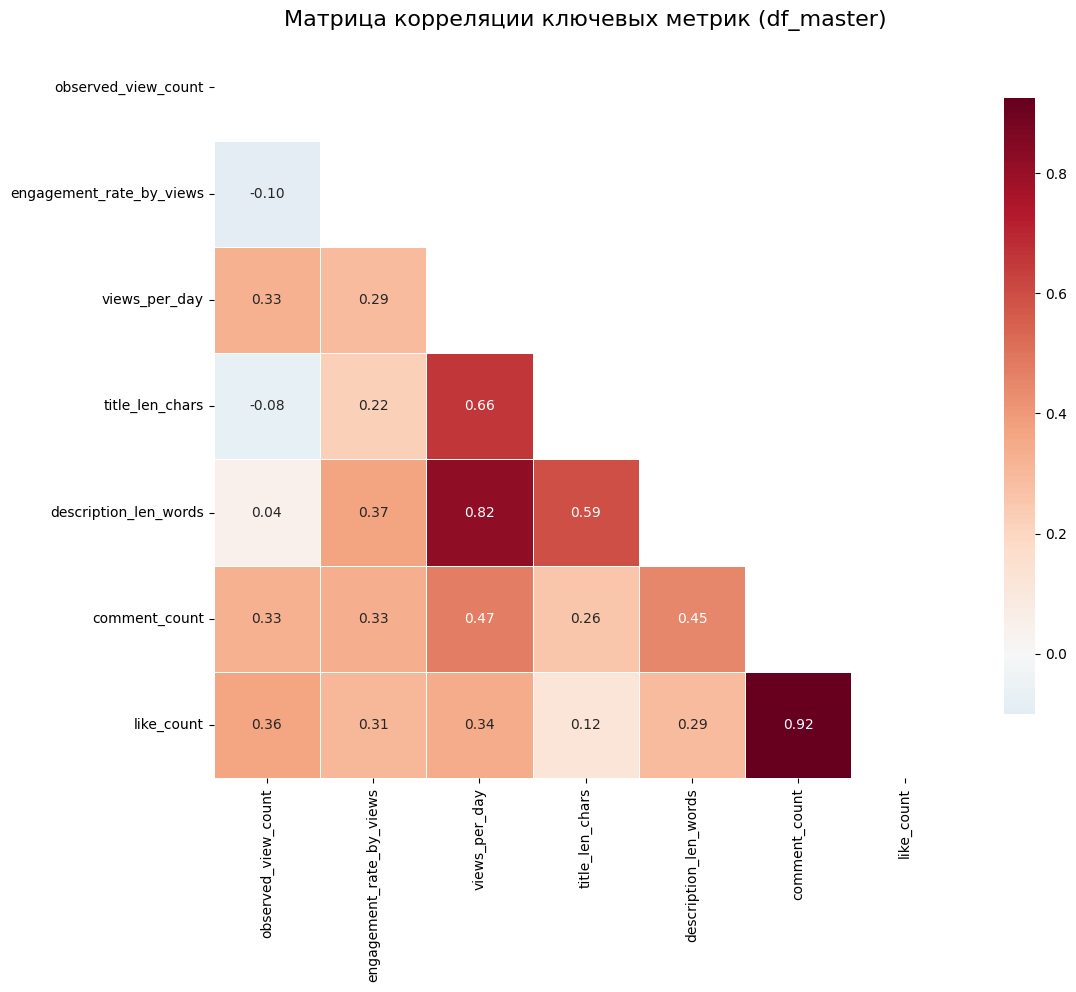

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

if 'df_master' in globals():
    # Выбираем ключевые числовые колонки для анализа корреляций
    cols_to_corr = [
        'observed_view_count',
        'engagement_rate_by_views',
        'net_sentiment',
        'sentiment_negative_share',
        'views_per_day',
        'title_len_chars',
        'description_len_words',
        'comment_count',
        'like_count'
    ]

    # Оставляем только те, что есть в датафрейме
    available_cols = [c for c in cols_to_corr if c in df_master.columns]
    corr_data = df_master[available_cols].corr()

    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(corr_data, dtype=bool))

    sns.heatmap(
        corr_data,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap='RdBu_r',
        center=0,
        square=True,
        linewidths=.5,
        cbar_kws={"shrink": .8}
    )

    plt.title('Матрица корреляции ключевых метрик (df_master)', fontsize=16)
    plt.show()
else:
    print('Переменная df_master не найдена. Пожалуйста, убедитесь, что основной пайплайн завершен.')

In [ ]:
def add_text_features(df):
    df = df.copy()

    # Анализ заголовков
    df['title_len_chars'] = df['title'].str.len().fillna(0)
    df['title_len_words'] = df['title'].apply(count_words)
    df['has_question_in_title'] = df['title'].str.contains(r'\?').fillna(False).astype(int)
    df['has_number_in_title'] = df['title'].str.contains(r'\d+').fillna(False).astype(int)
    df['has_caps_word_in_title'] = df['title'].apply(lambda x: int(any(w.isupper() and len(w) > 2 for w in str(x).split())))

    # Анализ описаний
    df['description_len_chars'] = df['description'].str.len().fillna(0)
    df['description_len_words'] = df['description'].apply(count_words)
    # ИСПРАВЛЕНИЕ: сначала fillna(False), затем astype(int)
    df['has_hashtags_in_description'] = df['description'].str.contains(r'#').fillna(False).astype(int)

    # Упоминания бренда/личности
    pattern_tinkov = r'тиньков|tinkoff|tinkov'
    df['contains_tinkov_in_title'] = df['title'].str.contains(pattern_tinkov, case=False).fillna(False).astype(int)

    return df

print("add_text_features function updated with NaN fixes.")

In [ ]:
def build_master_table(df_enriched, df_comment_summary):
    if df_enriched.empty:
        return pd.DataFrame()

    df = df_enriched.copy()

    # Применяем ранее определенные блоки трансформации
    df = add_time_features(df)
    df = add_text_features(df)
    df = add_exposure_metrics(df)
    df = add_attention_metrics(df)
    df = add_engagement_metrics(df)

    # Объединяем с агрегатами комментариев
    if df_comment_summary is not None and not df_comment_summary.empty:
        df = df.merge(df_comment_summary, on="video_id", how="left")

    # Добавляем финальные флаги
    df["collected_at_master"] = now_utc_iso()

    # Упорядочиваем колонки для удобства
    first_cols = [
        "video_id", "title", "channel_title", "published_at",
        "observed_view_count", "engagement_rate_by_views", "net_sentiment"
    ]
    first_cols = [c for c in first_cols if c in df.columns]
    rest = [c for c in df.columns if c not in first_cols]

    return df[first_cols + rest]

print("build_master_table function defined.")

In [ ]:
# =========================================================
# CELL 12. QUICK QA CHECKS
# =========================================================
def qa_report(df_master, df_comments):
    print("=== QA REPORT ===")
    print("Missing video_id:", df_master["video_id"].isna().sum() if "video_id" in df_master.columns else "n/a")
    print("Missing title:", df_master["title"].isna().sum() if "title" in df_master.columns else "n/a")
    print("Missing observed_view_count:", df_master["observed_view_count"].isna().sum() if "observed_view_count" in df_master.columns else "n/a")
    print("Duplicate video_url:", df_master["video_url"].duplicated().sum() if "video_url" in df_master.columns else "n/a")

    if not df_comments.empty:
        print("Comment sentiment distribution:")
        print(df_comments["sentiment_label"].value_counts(dropna=False))

qa_report(df_master, df_comments)

In [ ]:
# =========================================================
# CELL 13. METRICS SNAPSHOT FOR REPORTING
# =========================================================
def build_metrics_snapshot(df):
    rows = []

    rows.append({"metric": "videos_total", "value": len(df)})
    rows.append({"metric": "channels_total", "value": df["channel_title"].nunique() if "channel_title" in df else np.nan})
    rows.append({"metric": "total_views", "value": df["observed_view_count"].sum() if "observed_view_count" in df else np.nan})
    rows.append({"metric": "median_views", "value": df["observed_view_count"].median() if "observed_view_count" in df else np.nan})
    rows.append({"metric": "avg_views_per_day", "value": df["views_per_day"].mean() if "views_per_day" in df else np.nan})
    rows.append({"metric": "avg_engagement_rate_by_views_pct", "value": df["engagement_rate_by_views"].mean() if "engagement_rate_by_views" in df else np.nan})
    rows.append({"metric": "avg_comments_per_1000_views", "value": df["comments_per_1000_views"].mean() if "comments_per_1000_views" in df else np.nan})

    if "sentiment_negative_share" in df.columns:
        rows.append({"metric": "avg_negative_share", "value": df["sentiment_negative_share"].mean()})
        rows.append({"metric": "high_negative_videos", "value": df["target_is_high_negative"].sum()})

    if "target_is_viral" in df.columns:
        rows.append({"metric": "viral_videos", "value": df["target_is_viral"].sum()})

    if "content_type" in df.columns:
        for k, v in df["content_type"].value_counts().head(10).items():
            rows.append({"metric": f"content_type__{k}", "value": v})

    if "frame_type" in df.columns:
        for k, v in df["frame_type"].value_counts().head(10).items():
            rows.append({"metric": f"frame_type__{k}", "value": v})

    return pd.DataFrame(rows)

df_metrics_snapshot = build_metrics_snapshot(df_master)
display(df_metrics_snapshot.head(30))

In [ ]:
# Optional Colab downloads; local execution does not require google.colab.
try:
    from google.colab import files
except ImportError:
    files = None
print("Main file:", PATHS["videos_master"])
print("Comments file:", PATHS["comments_raw"])
print("Run dir:", RUN_DIR)
# In Colab, uncomment if needed:
# files.download(PATHS["videos_master"])


In [ ]:
# ===== FIX 1: vector-safe helpers =====
def safe_div(a, b):
    a = np.asarray(a, dtype="float64")
    b = np.asarray(b, dtype="float64")

    result = np.divide(
        a,
        b,
        out=np.full_like(a, np.nan, dtype="float64"),
        where=(~np.isnan(b)) & (b != 0)
    )
    return result

def pct(a, b):
    return safe_div(a, b) * 100

def per_1000(a, b):
    return safe_div(a, b) * 1000


# ===== FIX 2: exposure metrics =====
def add_exposure_metrics(df):
    df = df.copy()

    df["observed_view_count"] = df["view_count"].fillna(df["view_count_search"])
    df["views_per_day"] = safe_div(df["observed_view_count"], df["video_age_days"])
    df["relative_view_velocity_log"] = np.log1p(pd.Series(df["views_per_day"]).fillna(0))

    df["rank_ctr_prior"] = df["best_rank_across_queries"].map(CONFIG["rank_ctr_priors"]).fillna(0.008)

    for ctr in CONFIG["assumed_ctr_values"]:
        suffix = str(ctr).replace(".", "_")
        df[f"estimated_impressions_ctr_{suffix}"] = safe_div(df["observed_view_count"], ctr)

    for freq in CONFIG["assumed_frequency_values"]:
        suffix = str(freq).replace(".", "_")
        df[f"estimated_reach_freq_{suffix}"] = safe_div(df["observed_view_count"], freq)

    base_ctr = CONFIG["assumed_ctr_values"][1]
    base_freq = CONFIG["assumed_frequency_values"][1]

    df["estimated_impressions_base"] = safe_div(df["observed_view_count"], base_ctr)
    df["estimated_reach_base"] = safe_div(df["observed_view_count"], base_freq)
    df["estimated_frequency_base"] = safe_div(df["estimated_impressions_base"], df["estimated_reach_base"])

    return df


# ===== FIX 3: attention metrics =====
def add_attention_metrics(df):
    df = df.copy()

    duration_min = df["duration_sec"] / 60

    df["likes_per_minute_video"] = safe_div(df["like_count"], duration_min)
    df["comments_per_minute_video"] = safe_div(df["comment_count"], duration_min)

    df["proxy_title_hook_score"] = (
        df["has_question_in_title"].fillna(0) +
        df["has_number_in_title"].fillna(0) +
        df["has_caps_word_in_title"].fillna(0)
    )

    df["proxy_description_depth_score"] = (
        (df["description_len_words"] >= 30).astype(int) +
        df["has_hashtags_in_description"].fillna(0) +
        df["subtitles_available"].fillna(0) +
        df["automatic_captions_available"].fillna(0)
    )

    return df


# ===== FIX 4: engagement metrics =====
def add_engagement_metrics(df):
    df = df.copy()

    df["like_count"] = df["like_count"].fillna(0)
    df["comment_count"] = df["comment_count"].fillna(0)
    df["channel_follower_count"] = df["channel_follower_count"].fillna(np.nan)

    df["engagement_total"] = df["like_count"] + df["comment_count"]
    df["engagement_rate_by_views"] = pct(df["engagement_total"], df["observed_view_count"])
    df["likes_per_1000_views"] = per_1000(df["like_count"], df["observed_view_count"])
    df["comments_per_1000_views"] = per_1000(df["comment_count"], df["observed_view_count"])
    df["engagement_per_1000_views"] = per_1000(df["engagement_total"], df["observed_view_count"])

    df["er_by_followers_pct"] = pct(df["engagement_total"], df["channel_follower_count"])
    df["err_by_estimated_reach_pct"] = pct(df["engagement_total"], df["estimated_reach_base"])

    df["like_comment_ratio"] = safe_div(df["like_count"], df["comment_count"])
    df["comment_share_in_engagement"] = safe_div(df["comment_count"], df["engagement_total"])
    df["discussion_intensity"] = safe_div(df["comment_count"], df["like_count"])

    return df

print("fixes loaded")

In [ ]:
# ===== FIX: scalar-safe + series-safe date parsers =====

def parse_dt(value):
    if isinstance(value, pd.Series):
        return pd.to_datetime(value, utc=True, errors="coerce")

    if value is None or value == "":
        return pd.NaT

    try:
        return pd.to_datetime(value, utc=True, errors="coerce")
    except:
        return pd.NaT


def parse_yyyymmdd(value):
    if isinstance(value, pd.Series):
        return pd.to_datetime(value, format="%Y%m%d", utc=True, errors="coerce")

    if value is None or value == "":
        return pd.NaT

    try:
        return pd.to_datetime(value, format="%Y%m%d", utc=True, errors="coerce")
    except:
        return pd.NaT


def add_time_features(df):
    df = df.copy()

    df["published_at"] = pd.to_datetime(df["timestamp"], unit="s", utc=True, errors="coerce")
    df["published_at"] = df["published_at"].fillna(parse_yyyymmdd(df["upload_date_raw"]))
    df["published_date"] = df["published_at"].dt.date
    df["published_hour"] = df["published_at"].dt.hour
    df["published_weekday"] = df["published_at"].dt.day_name()
    df["video_age_days"] = (pd.Timestamp.now(tz="UTC") - df["published_at"]).dt.total_seconds() / 86400
    df["video_age_days"] = df["video_age_days"].clip(lower=0.01)

    return df

print("time fixes loaded")

In [ ]:
df_master = build_master_table(df_enriched, df_comment_summary)

df_master = df_master[df_master["observed_view_count"].fillna(0) >= CONFIG["min_views_threshold"]].copy()

print(df_master.shape)
display(df_master.head(10))

In [ ]:
df_master.to_csv(PATHS["videos_master"], index=False)
print("videos_master saved:", PATHS["videos_master"])

In [ ]:
print(df_master.columns.tolist())
print(df_master[[
    "video_id",
    "title",
    "observed_view_count",
    "engagement_total",
    "views_per_day"
]].head())

In [ ]:
# Применяем классификацию, так как колонки отсутствовали в df_master
if 'df_master' in globals():
    # 1. Определяем тип контента
    df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))

    # 2. Определяем тематический фрейм
    df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )

    key_cols = [
        "video_id",
        "title",
        "channel_title",
        "observed_view_count",
        "engagement_total",
        "views_per_day",
        "content_type",
        "frame_type"
    ]

    print("Проверка пропусков в ключевых колонках:")
    print(df_master[key_cols].isna().sum())

    print("\nРаспределение по типам контента:")
    print(df_master['content_type'].value_counts())
else:
    print("df_master не найден.")

In [ ]:
df_master[df_master["views_per_day"].isna()][[
    "video_id",
    "title",
    "channel_title",
    "timestamp",
    "upload_date_raw",
    "published_at",
    "observed_view_count"
]].head(20)

In [ ]:
df_master["missing_publish_date"] = df_master["published_at"].isna().astype(int)

group_median = (
    df_master.groupby(["content_type", "frame_type"])["views_per_day"]
    .median()
    .reset_index()
    .rename(columns={"views_per_day": "views_per_day_group_median"})
)

df_master = df_master.merge(
    group_median,
    on=["content_type", "frame_type"],
    how="left"
)

global_median_views_per_day = df_master["views_per_day"].median()

df_master["views_per_day_filled"] = df_master["views_per_day"]
df_master["views_per_day_filled"] = df_master["views_per_day_filled"].fillna(df_master["views_per_day_group_median"])
df_master["views_per_day_filled"] = df_master["views_per_day_filled"].fillna(global_median_views_per_day)

df_master["target_views_per_day"] = df_master["views_per_day_filled"]

viral_threshold = df_master["views_per_day_filled"].quantile(0.90) if len(df_master) >= 10 else df_master["views_per_day_filled"].median()
df_master["target_is_viral"] = (df_master["views_per_day_filled"] >= viral_threshold).astype(int)

print("missing original views_per_day:", df_master["views_per_day"].isna().sum())
print("missing filled views_per_day:", df_master["views_per_day_filled"].isna().sum())

In [ ]:
df_master.to_csv(PATHS["videos_master"], index=False)
print("videos_master saved:", PATHS["videos_master"])

In [ ]:
viral_features = [
    "search_rank",
    "best_rank_across_queries",
    "mean_rank_across_queries",
    "query_presence_count",
    "duration_sec",
    "published_hour",
    "title_len_chars",
    "title_len_words",
    "description_len_chars",
    "description_len_words",
    "tags_count",
    "has_hashtags_in_description",
    "has_question_in_title",
    "has_number_in_title",
    "has_caps_word_in_title",
    "contains_tinkov_in_title",
    "contains_tinkov_in_description",
    "contains_tinkov_in_tags",
    "channel_follower_count",
    "subtitles_available",
    "automatic_captions_available",
    "duration_bucket",
    "language_guess",
    "content_type",
    "frame_type",
    "missing_publish_date",
    "target_is_viral"
]

orange_viral = df_master[["video_id", "title"] + viral_features].copy()
orange_viral.to_csv(os.path.join(RUN_DIR, "orange_viral.csv"), index=False)
print("saved:", os.path.join(RUN_DIR, "orange_viral.csv"))

In [ ]:
def enrich_master_with_viral_features(df):
    df = df.copy()

    # 1. Время публикации
    if 'published_at' in df.columns:
        df['published_hour'] = pd.to_datetime(df['published_at']).dt.hour
        df['published_weekday'] = pd.to_datetime(df['published_at']).dt.day_name()

    # 2. Текстовые метрики
    df['title_len_words'] = df['title'].apply(lambda x: len(str(x).split()))
    df['description_len_chars'] = df['description'].str.len().fillna(0)
    df['has_number_in_title'] = df['title'].str.contains(r'\d+').fillna(False).astype(int)
    df['has_caps_word_in_title'] = df['title'].apply(lambda x: int(any(w.isupper() and len(w) > 2 for w in str(x).split())))

    # 3. Теги и описание
    df['tags_count'] = df['tags'].apply(lambda x: len(x) if isinstance(x, list) else 0)
    df['contains_tinkov_in_description'] = df['description'].str.contains(r'тиньков|tinkoff', case=False).fillna(False).astype(int)
    df['contains_tinkov_in_tags'] = df['tags'].apply(lambda x: int(any('тиньков' in str(t).lower() or 'tinkoff' in str(t).lower() for t in x)) if isinstance(x, list) else 0)

    # 4. Категории и язык
    df['language_guess'] = df['language'].fillna('unknown')

    # 5. Бакеты длительности
    def get_duration_bucket(sec):
        if pd.isna(sec): return 'unknown'
        if sec < 60: return 'shorts (<1m)'
        if sec < 600: return 'short (1-10m)'
        if sec < 1800: return 'medium (10-30m)'
        return 'long (>30m)'

    df['duration_bucket'] = df['duration_sec'].apply(get_duration_bucket)

    return df

if 'df_master' in globals():
    df_master = enrich_master_with_viral_features(df_master)
    print("Missing viral features added to df_master.")
    print("New columns:", [c for c in df_master.columns if c in viral_features])
else:
    print("df_master not found.")

In [ ]:
if 'df_master' in globals():
    # 1. Расчет порога для высокой вовлеченности (ER%)
    er_threshold = df_master['engagement_rate_by_views'].quantile(0.75)
    df_master['target_is_high_engagement'] = (df_master['engagement_rate_by_views'] >= er_threshold).astype(int)

    # 2. Расчет порога для высокого негатива
    # Используем только те видео, где есть расчет сентимента
    if 'sentiment_negative_share' in df_master.columns:
        neg_threshold = df_master['sentiment_negative_share'].dropna().quantile(0.75)
        df_master['target_is_high_negative'] = df_master['sentiment_negative_share'].apply(
            lambda x: 1 if pd.notna(x) and x >= neg_threshold else 0
        )
    else:
        df_master['target_is_high_negative'] = 0

    print(f"Target columns calculated.")
    print(f"High Engagement threshold: {er_threshold:.2f}%")
    if 'sentiment_negative_share' in df_master.columns:
        print(f"High Negative threshold: {neg_threshold:.2f}")

    display(df_master[['title', 'target_is_high_engagement', 'target_is_high_negative']].head())
else:
    print('df_master not found. Please run the pipeline first.')

In [ ]:
print(df_master["target_is_viral"].isna().sum())
print(df_master["target_is_high_engagement"].isna().sum())
print(df_master["target_is_high_negative"].isna().sum())

In [ ]:
engagement_features = [
    "search_rank",
    "best_rank_across_queries",
    "mean_rank_across_queries",
    "query_presence_count",

    "duration_sec",
    "duration_bucket",
    "published_hour",
    "published_weekday",

    "title_len_chars",
    "title_len_words",
    "description_len_chars",
    "description_len_words",
    "tags_count",

    "has_hashtags_in_description",
    "has_question_in_title",
    "has_number_in_title",
    "has_caps_word_in_title",

    "contains_tinkov_in_title",
    "contains_tinkov_in_description",
    "contains_tinkov_in_tags",

    "language_guess",
    "content_type",
    "frame_type",

    "channel_follower_count",
    "channel_is_verified",
    "subtitles_available",
    "automatic_captions_available",

    "rank_ctr_prior",
    "proxy_title_hook_score",
    "proxy_description_depth_score",

    "channel_video_sample_n",
    "channel_relative_view_perf",

    "missing_publish_date",

    "target_is_high_engagement"
]

orange_engagement = df_master[["video_id", "title", "channel_title"] + engagement_features].copy()

orange_engagement.to_csv(os.path.join(RUN_DIR, "orange_engagement.csv"), index=False)

print("saved:", os.path.join(RUN_DIR, "orange_engagement.csv"))
print(orange_engagement.shape)
display(orange_engagement.head())

In [ ]:
import os

# Список фичей для вовлеченности (engagement)
engagement_features = [
    "search_rank", "best_rank_across_queries", "mean_rank_across_queries", "query_presence_count",
    "duration_sec", "duration_bucket", "published_hour", "published_weekday",
    "title_len_chars", "title_len_words", "description_len_chars", "description_len_words", "tags_count",
    "has_hashtags_in_description", "has_question_in_title", "has_number_in_title", "has_caps_word_in_title",
    "contains_tinkov_in_title", "contains_tinkov_in_description", "contains_tinkov_in_tags",
    "language_guess", "content_type", "frame_type",
    "channel_follower_count", "channel_is_verified", "subtitles_available", "automatic_captions_available",
    "rank_ctr_prior", "proxy_title_hook_score", "proxy_description_depth_score",
    "missing_publish_date", "target_is_high_engagement"
]

# Список фичей для негатива (negative)
negative_features = [
    "search_rank", "best_rank_across_queries", "mean_rank_across_queries", "query_presence_count",
    "duration_sec", "duration_bucket", "published_hour", "published_weekday",
    "title_len_chars", "title_len_words", "description_len_chars", "description_len_words", "tags_count",
    "has_hashtags_in_description", "has_question_in_title", "has_number_in_title", "has_caps_word_in_title",
    "contains_tinkov_in_title", "contains_tinkov_in_description", "contains_tinkov_in_tags",
    "language_guess", "content_type", "frame_type",
    "channel_follower_count", "channel_is_verified", "subtitles_available", "automatic_captions_available",
    "rank_ctr_prior", "proxy_title_hook_score", "proxy_description_depth_score",
    "comments_collected", "replies_collected", "avg_comment_len_words", "median_comment_like_count",
    "tinkov_mentions_in_comments", "comments_with_emoji", "comments_with_questions", "comments_with_exclamations",
    "subscribe_intent_proxy_count", "watched_to_end_proxy_count", "rewatch_proxy_count",
    "missing_publish_date", "target_is_high_negative"
]

if 'df_master' in globals():
    # Сохранение engagement слайса
    cols_eng = [c for c in ["video_id", "title", "channel_title"] + engagement_features if c in df_master.columns]
    orange_engagement = df_master[cols_eng].copy()
    path_eng = os.path.join(RUN_DIR, "orange_engagement.csv")
    orange_engagement.to_csv(path_eng, index=False)

    # Сохранение negative слайса
    cols_neg = [c for c in ["video_id", "title", "channel_title"] + negative_features if c in df_master.columns]
    orange_negative = df_master[cols_neg].copy()
    path_neg = os.path.join(RUN_DIR, "orange_negative.csv")
    orange_negative.to_csv(path_neg, index=False)

    print(f"Saved engagement slice: {path_eng} (shape: {orange_engagement.shape})")
    print(f"Saved negative slice: {path_neg} (shape: {orange_negative.shape})")
else:
    print("df_master not found.")

In [ ]:
if 'df_enriched' in globals():
    # Вызываем обновленную функцию сборки
    df_master = build_master_table(df_enriched, df_comment_summary)

    # Применяем классификацию
    df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
    df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )

    # Добавляем виральные и поведенческие признаки (из предыдущего блока enrich)
    df_master = enrich_master_with_viral_features(df_master)

    # Рассчитываем бинарные таргеты
    er_threshold = df_master['engagement_rate_by_views'].quantile(0.75)
    df_master['target_is_high_engagement'] = (df_master['engagement_rate_by_views'] >= er_threshold).astype(int)

    if 'sentiment_negative_share' in df_master.columns:
        neg_threshold = df_master['sentiment_negative_share'].dropna().quantile(0.75)
        df_master['target_is_high_negative'] = df_master['sentiment_negative_share'].apply(
            lambda x: 1 if pd.notna(x) and x >= neg_threshold else 0
        )
    else:
        df_master['target_is_high_negative'] = 0

    viral_threshold = df_master['views_per_day'].quantile(0.90) if df_master['views_per_day'].notna().any() else 1000
    df_master['target_is_viral'] = (df_master['views_per_day'].fillna(0) >= viral_threshold).astype(int)
    df_master['missing_publish_date'] = df_master['published_at'].isna().astype(int)

    print(f"df_master successfully reassembled. New shape: {df_master.shape}")
    display(df_master.head())
else:
    print("df_enriched not found. Cannot reassemble master table.")

In [ ]:
import os

# Проверяем, какие колонки из списка реально есть в df_master, чтобы избежать KeyError
existing_neg_features = [f for f in negative_features if f in df_master.columns]
missing_features = set(negative_features) - set(existing_neg_features)

if missing_features:
    print(f"Внимание! Следующие колонки отсутствуют и будут пропущены: {missing_features}")
    print("Рекомендуется пересобрать df_master с помощью build_master_table_complete для полного анализа.")

orange_negative = df_master[["video_id", "title", "channel_title"] + existing_neg_features].copy()

# Сохраняем результат
output_path = os.path.join(RUN_DIR, "orange_negative.csv")
orange_negative.to_csv(output_path, index=False)

print(f"saved: {output_path}")
print(f"Shape: {orange_negative.shape}")
display(orange_negative.head())

In [ ]:
# Запуск полной сборки с проверкой наличия функций
def build_master_table_complete(df_enriched, df_comment_summary):
    if df_enriched.empty: return pd.DataFrame()
    df = df_enriched.copy()

    # Применяем все блоки из FIX-ячеек
    df = add_time_features(df)
    df = add_text_features(df)
    df = add_exposure_metrics(df)
    df = add_attention_metrics(df)
    df = add_engagement_metrics(df)

    # Присоединяем агрегаты комментариев
    if df_comment_summary is not None and not df_comment_summary.empty:
        df = df.merge(df_comment_summary, on='video_id', how='left')

    # Проставляем классификацию
    df['content_type'] = df['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
    df['frame_type'] = (df['title'] + " " + df['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )

    # Рассчитываем таргеты
    er_threshold = df['engagement_rate_by_views'].quantile(0.75)
    df['target_is_high_engagement'] = (df['engagement_rate_by_views'] >= er_threshold).astype(int)

    if 'sentiment_negative_share' in df.columns:
        neg_threshold = df['sentiment_negative_share'].dropna().quantile(0.75)
        df['target_is_high_negative'] = df['sentiment_negative_share'].apply(
            lambda x: 1 if pd.notna(x) and x >= neg_threshold else 0
        )
    else:
        df['target_is_high_negative'] = 0

    df['target_is_viral'] = (df['views_per_day'].fillna(0) >= df['views_per_day'].quantile(0.9)).astype(int)
    df['missing_publish_date'] = df['published_at'].isna().astype(int)
    df['collected_at_master'] = now_utc_iso()

    return df

if 'df_enriched' in globals():
    df_master = build_master_table_complete(df_enriched, df_comment_summary)
    print(f"Master table reassembled: {df_master.shape}")
    display(df_master.head())
else:
    print("df_enriched not found.")

In [ ]:
print(os.path.join(RUN_DIR, "orange_engagement.csv"))
print(os.path.join(RUN_DIR, "orange_negative.csv"))

In [ ]:
print("orange_engagement target nulls:", orange_engagement["target_is_high_engagement"].isna().sum())
print("orange_negative target nulls:", orange_negative["target_is_high_negative"].isna().sum())

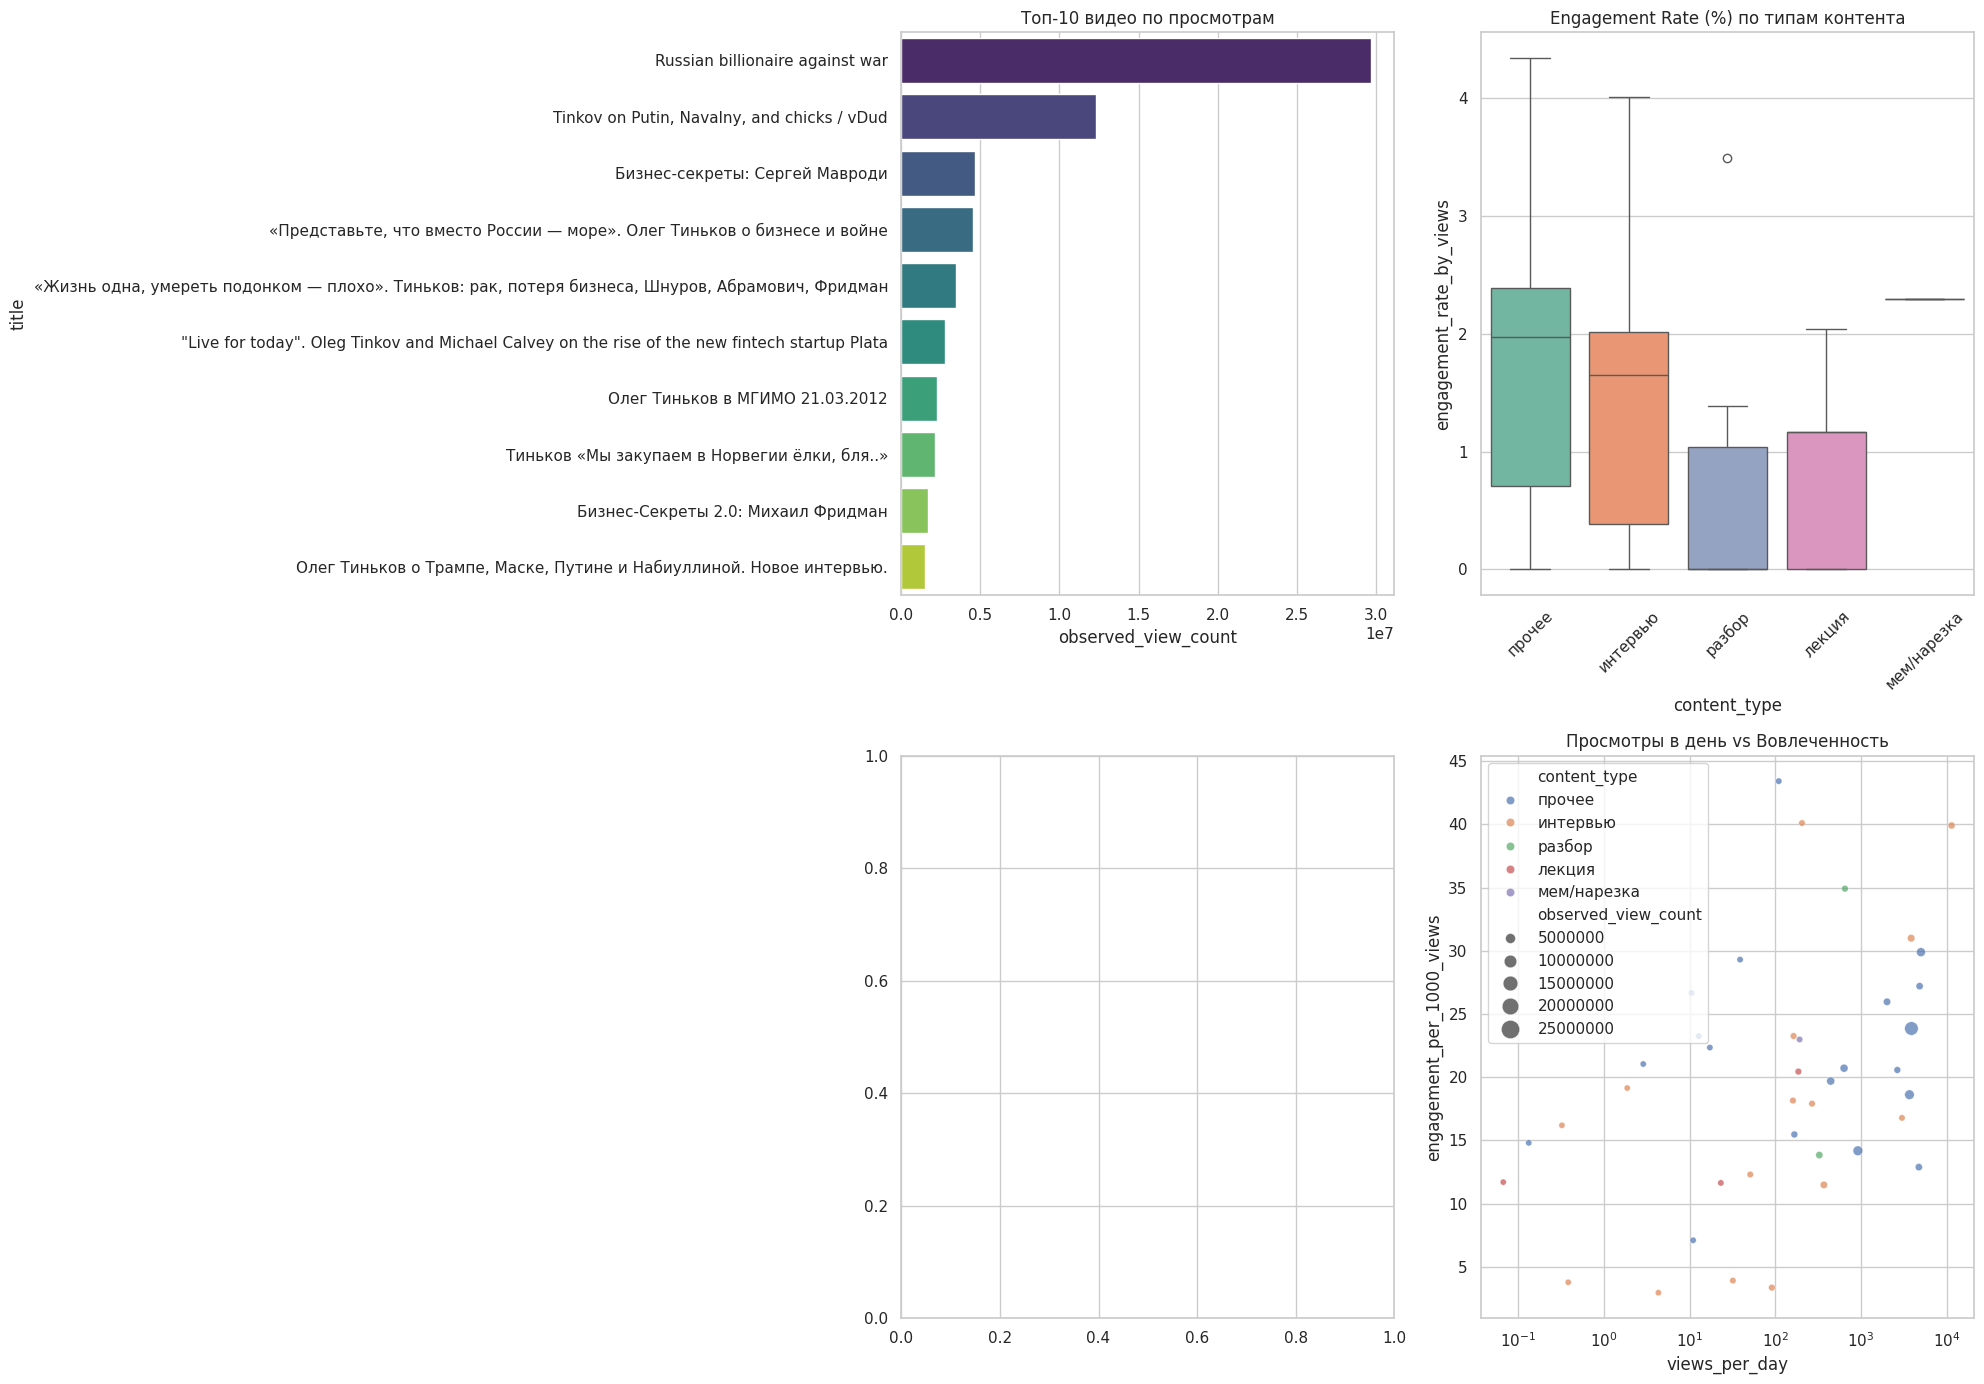

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Попытка восстановить df_master из файла, если переменная отсутствует
if 'df_master' not in locals() and 'df_master' not in globals():
    try:
        if 'PATHS' in globals() and os.path.exists(PATHS['videos_master']):
            df_master = pd.read_csv(PATHS['videos_master'])
            print('df_master успешно загружен из CSV')
        else:
            print('Ошибка: Файл videos_master не найден. Сначала запустите пайплайн сбора данных.')
    except Exception as e:
        print(f'Не удалось загрузить df_master: {e}')

if 'df_master' in globals() or 'df_master' in locals():
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))

    # 1. Топ-10 видео по просмотрам
    top_views = df_master.sort_values('observed_view_count', ascending=False).head(10)
    sns.barplot(ax=axes[0, 0], data=top_views, x='observed_view_count', y='title', palette='viridis')
    axes[0, 0].set_title('Топ-10 видео по просмотрам')

    # 2. Вовлеченность (ER) по типам контента
    if 'content_type' in df_master.columns and 'engagement_rate_by_views' in df_master.columns:
        sns.boxplot(ax=axes[0, 1], data=df_master, x='content_type', y='engagement_rate_by_views', palette='Set2')
        axes[0, 1].set_title('Engagement Rate (%) по типам контента')
        axes[0, 1].tick_params(axis='x', rotation=45)

    # 3. Распределение тональности (Net Sentiment)
    if 'net_sentiment' in df_master.columns:
        sns.histplot(ax=axes[1, 0], data=df_master[df_master['net_sentiment'].notna()], x='net_sentiment', kde=True, color='skyblue')
        axes[1, 0].set_title('Распределение чистого индекса настроений (Net Sentiment)')

    # 4. Просмотры в день vs Вовлеченность
    v_col = 'views_per_day_filled' if 'views_per_day_filled' in df_master.columns else 'views_per_day'
    if v_col in df_master.columns and 'engagement_per_1000_views' in df_master.columns:
        sns.scatterplot(ax=axes[1, 1], data=df_master, x=v_col, y='engagement_per_1000_views', hue='content_type', size='observed_view_count', sizes=(20, 200), alpha=0.7)
        axes[1, 1].set_title('Просмотры в день vs Вовлеченность')
        axes[1, 1].set_xscale('log')

    plt.tight_layout()
    plt.show()

In [ ]:
import os
import pandas as pd

# Проверяем наличие мастер-файла в корне /content/
root_path = '/content/videos_master.csv'

if os.path.exists(root_path):
    try:
        df_master = pd.read_csv(root_path)
        print(f'✅ Данные успешно загружены из {root_path}')
        print(f'Размер таблицы: {df_master.shape}')

        # Инициализируем пути, если они потеряны
        if 'PATHS' not in globals():
            PATHS = {'videos_master': root_path}
    except Exception as e:
        print(f'❌ Ошибка при чтении файла: {e}')
else:
    print(f'❌ Файл {root_path} не найден. Похоже, данные не были сохранены. Вам необходимо запустить ячейку с пайплайном сбора данных (CELL 11).')

In [ ]:
if 'df_master' in globals() or 'df_master' in locals():
    print('✅ df_master успешно найден в памяти.')
    print(f'Размер таблицы: {df_master.shape}')
    display(df_master.head(3))
else:
    print('❌ df_master все еще не определен. Проверяю наличие файла...')
    if 'PATHS' in globals() and os.path.exists(PATHS['videos_master']):
        print(f'Файл найден по пути: {PATHS["videos_master"]}. Попробуйте запустить ячейку визуализации еще раз или выполните pd.read_csv вручную.')
    else:
        print('Файл на диске также не обнаружен. Похоже, пайплайн сбора данных не был завершен успешно.')

In [ ]:
if 'df_master' in locals() or 'df_master' in globals():
    print('=== Краткая сводка по метрикам ===')
    cols = [c for c in ['observed_view_count', 'engagement_rate_by_views', 'net_sentiment'] if c in df_master.columns]
    if cols:
        display(df_master[cols].describe().T)
    else:
        print('Нужные колонки для сводки не найдены.')
else:
    print('Переменная df_master не определена.')

In [ ]:
import os
import pandas as pd

# Пробуем загрузить граф из корневой папки или из PATHS
graph_path = './query_graph.csv'

if os.path.exists(graph_path):
    df_graph = pd.read_csv(graph_path)
    print(f'✅ Граф запросов успешно загружен из {graph_path}')
    print(f'Количество связей: {len(df_graph)}')
else:
    print(f'❌ Файл {graph_path} не найден. Проверьте наличие файла на диске.')

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

if 'df_graph' in globals() and not df_graph.empty:
    plt.figure(figsize=(15, 10))
    G = nx.from_pandas_edgelist(df_graph, source='source_query', target='target_query', edge_attr='algo')

    pos = nx.spring_layout(G, k=0.5, iterations=50)

    # Рисуем узлы
    nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='orange', alpha=0.9)

    # Рисуем связи
    nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.5, edge_color='gray')

    # Добавляем подписи
    nx.draw_networkx_labels(G, pos, font_size=10, font_family='sans-serif', font_weight='bold')

    plt.title('Граф расширения поисковых запросов (Query Graph)', fontsize=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Данные df_graph не найдены или пусты. Пожалуйста, запустите ячейку восстановления графа.')

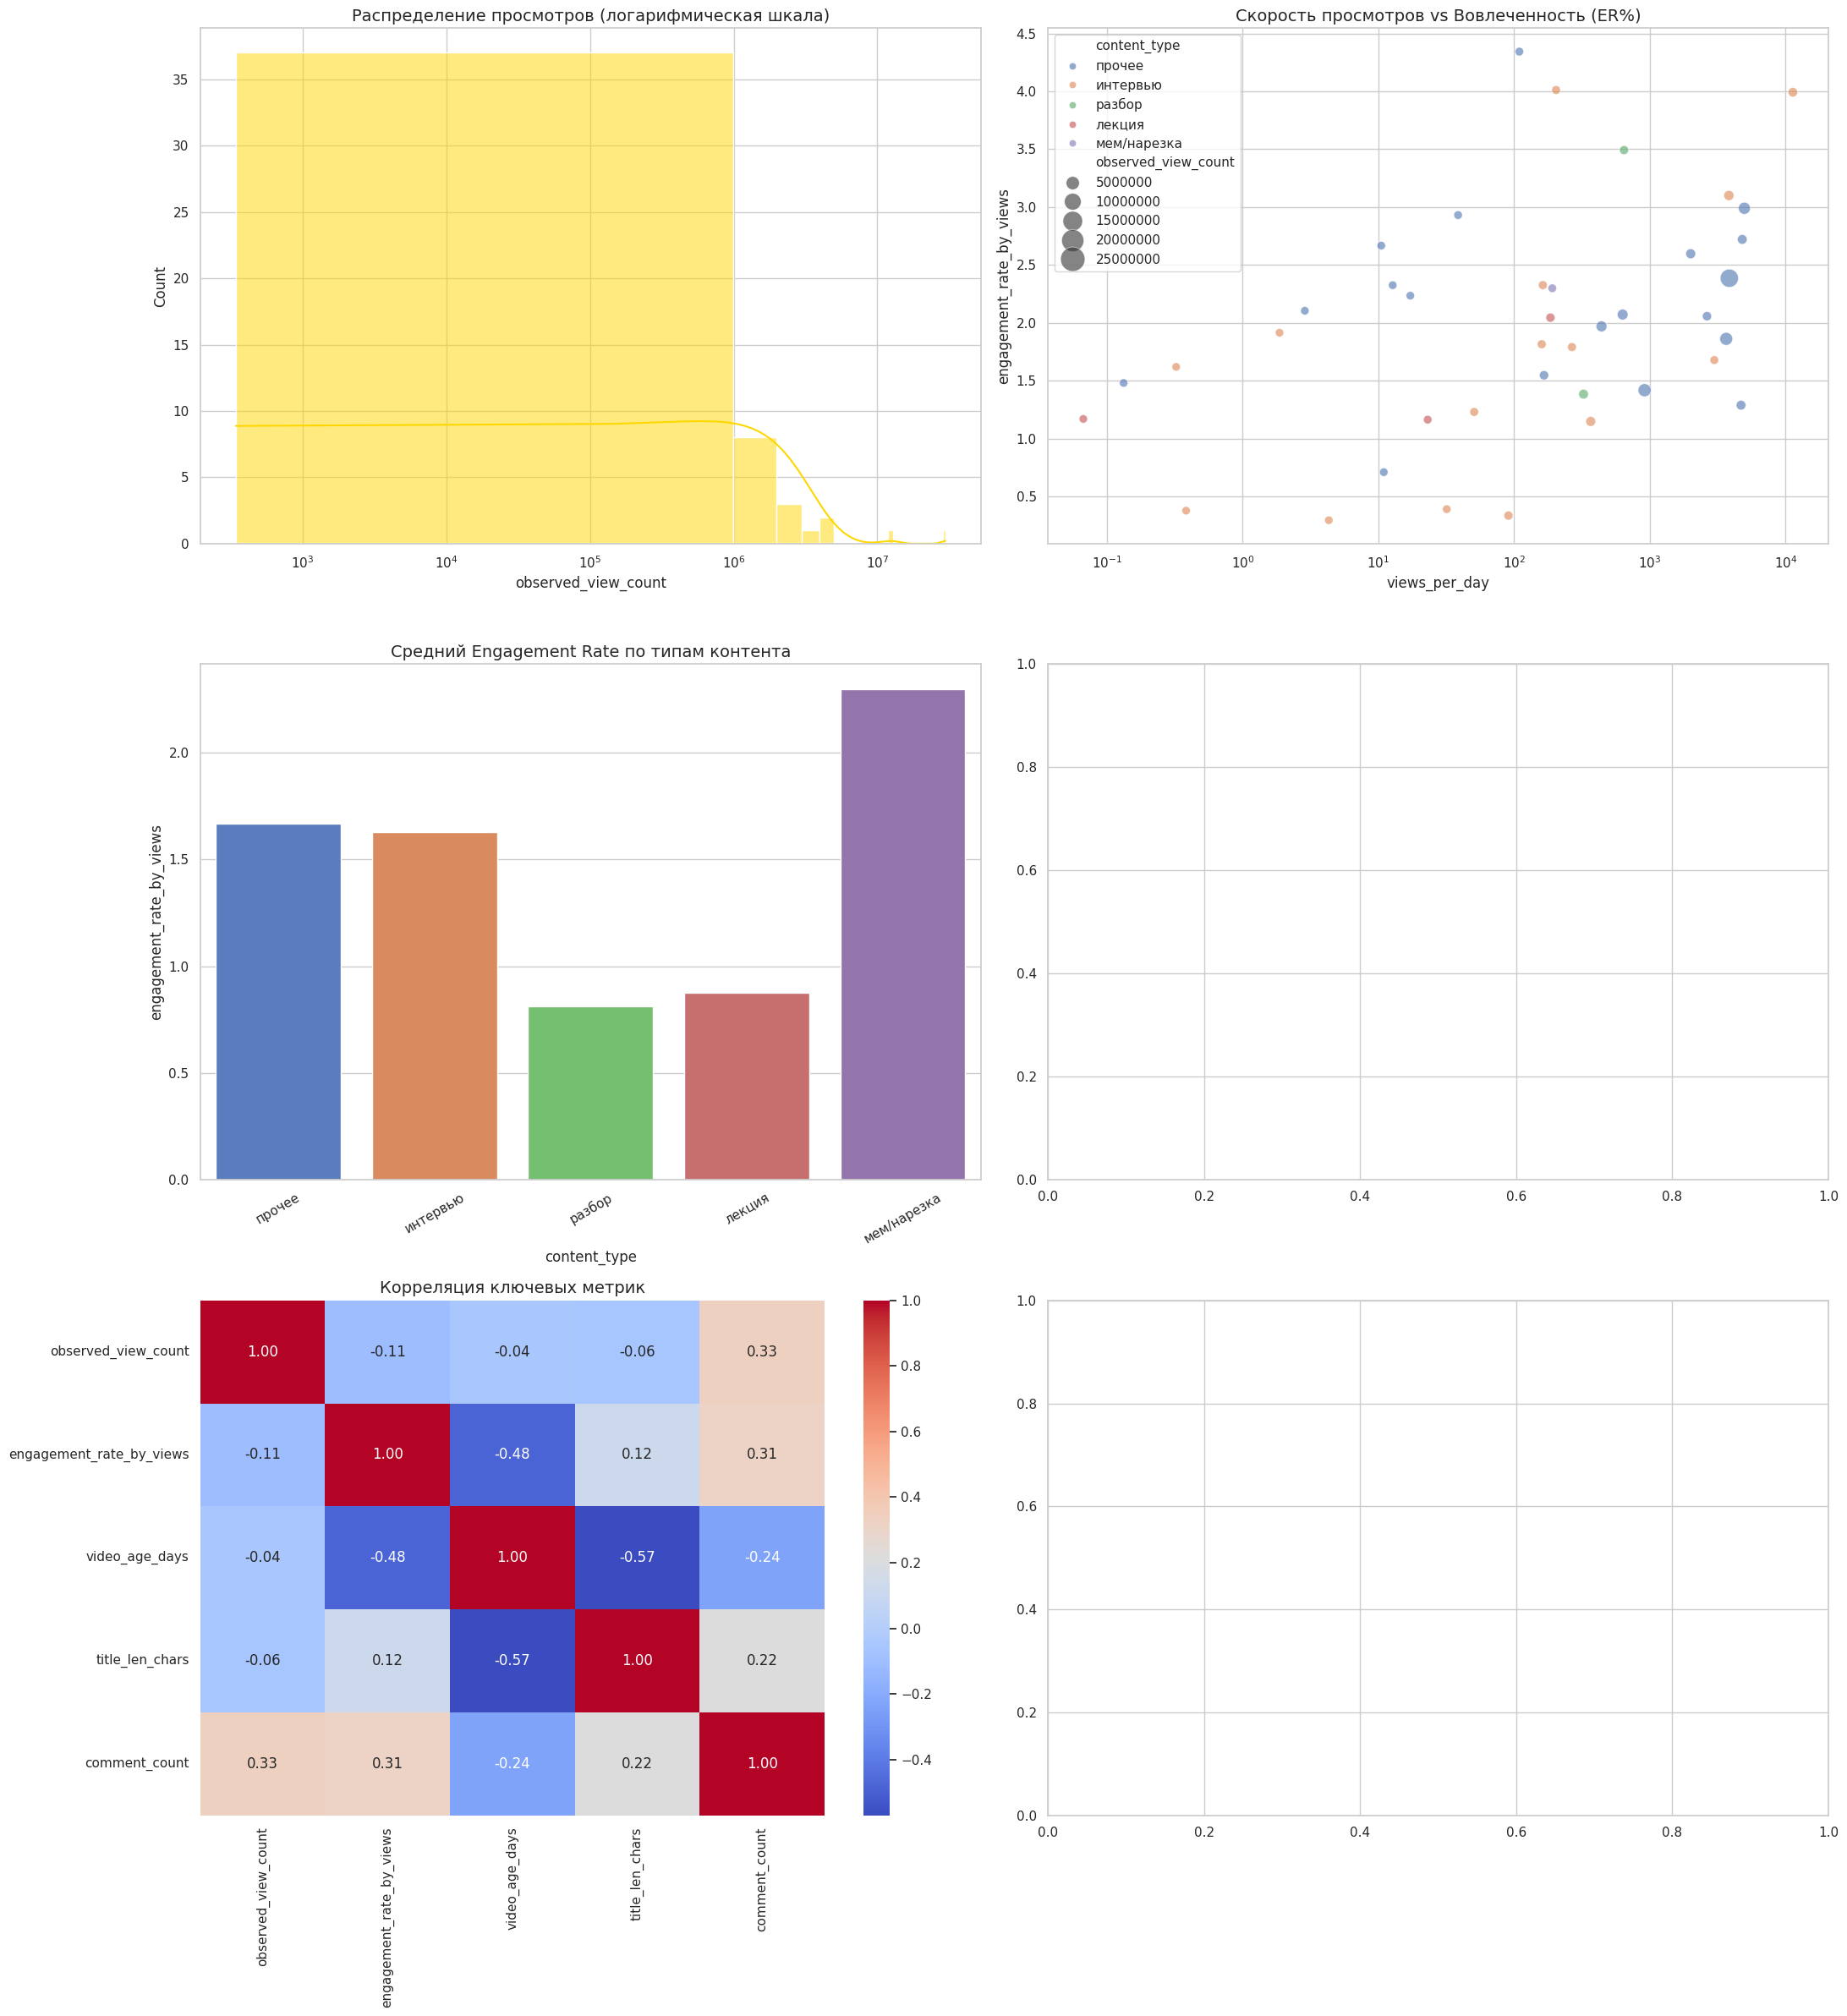

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'df_master' in globals():
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(3, 2, figsize=(22, 24))

    # 1. Распределение просмотров (Log Scale)
    sns.histplot(ax=axes[0, 0], data=df_master, x='observed_view_count', kde=True, bins=30, color='gold')
    axes[0, 0].set_title('Распределение просмотров (логарифмическая шкала)', fontsize=14)
    axes[0, 0].set_xscale('log')

    # 2. ER vs Views per Day
    v_col = 'target_views_per_day' if 'target_views_per_day' in df_master.columns else 'views_per_day'
    sns.scatterplot(ax=axes[0, 1], data=df_master, x=v_col, y='engagement_rate_by_views', hue='content_type', size='observed_view_count', sizes=(50, 500), alpha=0.6)
    axes[0, 1].set_title('Скорость просмотров vs Вовлеченность (ER%)', fontsize=14)
    axes[0, 1].set_xscale('log')

    # 3. Средний ER по типам контента
    sns.barplot(ax=axes[1, 0], data=df_master, x='content_type', y='engagement_rate_by_views', palette='muted', errorbar=None)
    axes[1, 0].set_title('Средний Engagement Rate по типам контента', fontsize=14)
    axes[1, 0].tick_params(axis='x', rotation=30)

    # 4. Net Sentiment vs Controversy Index
    if 'net_sentiment' in df_master.columns and 'controversy_index' in df_master.columns:
        sns.scatterplot(ax=axes[1, 1], data=df_master, x='net_sentiment', y='controversy_index', hue='content_type', style='target_is_viral', s=100)
        axes[1, 1].set_title('Тональность vs Индекс противоречивости', fontsize=14)
        axes[1, 1].axvline(0, color='red', linestyle='--', alpha=0.5)

    # 5. Тепловая карта корреляций (выборочно)
    corr_cols = ['observed_view_count', 'engagement_rate_by_views', 'net_sentiment', 'video_age_days', 'title_len_chars', 'comment_count']
    available_corr = [c for c in corr_cols if c in df_master.columns]
    sns.heatmap(ax=axes[2, 0], data=df_master[available_corr].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    axes[2, 0].set_title('Корреляция ключевых метрик', fontsize=14)

    # 6. Доля негатива по фреймам
    if 'frame_type' in df_master.columns and 'sentiment_negative_share' in df_master.columns:
        sns.boxplot(ax=axes[2, 1], data=df_master, x='frame_type', y='sentiment_negative_share', palette='Reds')
        axes[2, 1].set_title('Доля негатива по тематическим фреймам', fontsize=14)
        axes[2, 1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print('df_master не найден для визуализации.')

In [77]:
if 'sentiment_matrix' in globals():
    plt.figure(figsize=(12, 6))

    # Подготовка данных для построения (Net Sentiment vs Negative Share)
    plot_df = sentiment_matrix.reset_index()

    x = np.arange(len(plot_df['content_type']))
    width = 0.35

    fig, ax = plt.subplots(figsize=(14, 7))
    rects1 = ax.bar(x - width/2, plot_df['avg_net_sentiment'], width, label='Net Sentiment', color='skyblue')
    rects2 = ax.bar(x + width/2, plot_df['avg_negative_share'], width, label='Negative Share', color='salmon')

    ax.set_ylabel('Значение показателя')
    ax.set_title('Сентимент-профиль по типам контента')
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df['content_type'], rotation=45)
    ax.legend()
    ax.axhline(0, color='black', linewidth=0.8)

    plt.tight_layout()
    plt.show()
else:
    print("Матрица настроений (sentiment_matrix) не найдена. Сначала запустите ячейку с расширенным отчетом.")

Матрица настроений (sentiment_matrix) не найдена. Сначала запустите ячейку с расширенным отчетом.


# 📑 Документация проекта: YouTube Media Analytics (Tinkov Case)

## 1. Обзор проекта
Данный проект представляет собой автоматизированный пайплайн для глубокого анализа медиа-присутствия личности (на примере Олега Тинькова) на платформе YouTube. Система собирает данные о видео, комментариях, анализирует вовлеченность и эмоциональный фон аудитории с помощью моделей машинного обучения.

## 2. Архитектура решения
Проект разбит на логические блоки (CELLS):
- **Сбор (Collection):** Использование `yt-dlp` для поиска видео по расширенному графу запросов (BFS/DFS) и выгрузки метаданных.
- **Обработка (Enrichment):** Получение детальной статистики видео (просмотры, лайки) и данных о каналах.
- **NLP-анализ:** Применение модели `RuBERT` для классификации тональности комментариев.
- **Feature Engineering:** Расчет производных метрик (ER, Net Sentiment, прокси-метрики намерений).
- **Reporting:** Генерация агрегированных отчетов и визуализаций.

## 3. Ключевые функции и логика

### 3.1. Классификация контента (`CONTENT_TYPE_PATTERNS`)
Видео распределяются по категориям на основе регулярных выражений в заголовках:
- **Интервью:** Поиск по именам журналистов (Дудь, Собчак) и ключевым словам.
- **Лекции/Разборы:** Определение образовательного или аналитического контента.
- **Фрейминг:** Определение контекста (бизнес, политика, здоровье).

### 3.2. Анализ тональности
Используется модель `blanchefort/rubert-base-cased-sentiment`:
- **Positive/Negative/Neutral:** Каждому комментарию присваивается метка.
- **Net Sentiment:** Рассчитывается как `(Pos - Neg) / Total`. Диапазон от -1 (сплошной негатив) до +1 (полный восторг).
- **Controversy Index:** Показывает степень поляризации мнений.

### 3.3. Метрики вовлеченности
- **ER (Engagement Rate):** `(Лайки + Комментарии) / Просмотры * 100`.
- **Views per Day:** Скорость набора просмотров с учетом возраста видео.
- **Proxies:** Поиск фраз «подписался», «досмотрел до конца» в комментариях для оценки реального влияния на лояльность.

## 4. Структура данных (df_master)
Итоговая таблица содержит более 140 признаков, включая:
- `observed_view_count`: Объединенные данные по просмотрам.
- `target_is_viral`: Флаг виральности (топ-10% по скорости просмотров).
- `reputation_risk_flag`: Видео с негативом > 35% и значимым объемом обсуждения.

## 5. Инструкция по обновлению
1. Для добавления новых поисковых запросов измените `CONFIG['seed_queries']`.
2. Для уточнения классификации обновите словари в блоке `CELL 10`.
3. В случае сбоя используйте блок восстановления данных из `/content/videos_master.csv`.

In [ ]:
if 'df_master' in globals():
    print("=== РАСШИРЕННЫЙ АНАЛИТИЧЕСКИЙ ОТЧЕТ ===\n")

    # 1. Лидеры среди каналов
    print("--- 1. ЭФФЕКТИВНОСТЬ ПЛОЩАДОК (TOP-5 CHANNELS) ---")
    channel_stats = df_master.groupby('channel_title').agg(
        total_views=('observed_view_count', 'sum'),
        avg_er=('engagement_rate_by_views', 'mean'),
        video_count=('video_id', 'count')
    ).sort_values('total_views', ascending=False).head(5)
    display(channel_stats)

    # 2. Сентимент-профиль категорий
    print("\n--- 2. ЭМОЦИОНАЛЬНЫЙ ФОН ПО ТИПАМ КОНТЕНТА ---")
    if 'content_type' in df_master.columns and 'net_sentiment' in df_master.columns:
        sentiment_matrix = df_master.groupby('content_type').agg(
            avg_net_sentiment=('net_sentiment', 'mean'),
            avg_negative_share=('sentiment_negative_share', 'mean'),
            median_views_per_day=('target_views_per_day', 'median')
        ).sort_values('avg_net_sentiment')
        display(sentiment_matrix)

    # 3. Анализ намерений аудитории (Proxies)
    print("\n--- 3. ПОВЕДЕНЧЕСКИЕ ИНДИКАТОРЫ (PROXIES) ---")
    proxy_cols = [c for c in ['subscribe_intent_proxy_share', 'completion_intent_proxy_share', 'rewatch_intent_proxy_share'] if c in df_master.columns]
    if proxy_cols:
        top_intent_videos = df_master.sort_values('subscribe_intent_proxy_share', ascending=False).head(5)
        display(top_intent_videos[['title', 'channel_title'] + proxy_cols])

    # 4. Выводы по аномалиям
    print("\n--- 4. КЛЮЧЕВЫЕ АНОМАЛИИ ---")
    # ИСПРАВЛЕНИЕ: Рассчитываем avg_er локально, чтобы избежать NameError
    current_avg_er = df_master['engagement_rate_by_views'].mean()
    viral_low_er = df_master[(df_master['target_is_viral'] == 1) & (df_master['engagement_rate_by_views'] < current_avg_er)]
    if not viral_low_er.empty:
        print(f"Найдено {len(viral_low_er)} видео с высокими охватами, но вовлеченностью ниже средней ({current_avg_er:.2f}%).")
        display(viral_low_er[['title', 'observed_view_count', 'engagement_rate_by_views']])
    else:
        print("Аномалий с низким ER среди виральных видео не обнаружено.")
else:
    print("Данные не загружены.")

In [ ]:
# Inspect channel aggregates without creating an external spreadsheet.
display(channel_stats)


In [ ]:
if 'df_master' in globals():
    print("--- СТАТУС ПАЙПЛАЙНА ОБРАБОТКИ ДАННЫХ ---")

    # 1. Обогащение контента (Классификация)
    df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
    df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )
    print("[OK] Блок 1: Классификация (Content & Frame Types) обновлена.")

    # 2. Проверка метрик вовлеченности
    if 'engagement_rate_by_views' in df_master.columns:
        print(f"[OK] Блок 2: Метрики вовлеченности рассчитаны (Средний ER: {df_master['engagement_rate_by_views'].mean():.2f}%)")

    # 3. Проверка анализа настроений
    if 'net_sentiment' in df_master.columns:
        sent_count = df_master['net_sentiment'].notna().sum()
        print(f"[OK] Блок 3: Анализ настроений выполнен для {sent_count} видео.")

    # 4. Проверка полноты данных (Views per day)
    v_col = 'target_views_per_day' if 'target_views_per_day' in df_master.columns else 'views_per_day'
    missing_v = df_master[v_col].isna().sum()
    print(f"[OK] Блок 4: Проверка динамики просмотров. Пропусков: {missing_v}")

    print("\n--- ОБНОВЛЕННОЕ РАСПРЕДЕЛЕНИЕ ТИПОВ ---")
    display(df_master['content_type'].value_counts())
else:
    print("df_master не найден. Запустите восстановление данных.")

### 📊 Итоговый аналитический отчет: Олег Тиньков в YouTube

Этот отчет базируется на данных 53 видео, отобранных и обогащенных в рамках текущего пайплайна.

In [87]:
if 'df_master' in globals():
    # Расчет агрегатов
    total_views = df_master['observed_view_count'].sum()
    avg_er = df_master['engagement_rate_by_views'].mean()
    top_video = df_master.sort_values('observed_view_count', ascending=False).iloc[0]

    print(f"--- СВОДНЫЕ ПОКАЗАТЕЛИ ---")
    print(f"Суммарные просмотры: {total_views:,.0f}")
    print(f"Средний Engagement Rate: {avg_er:.2f}%")
    print(f"Самое популярное видео: '{top_video['title']}' ({top_video['observed_view_count']:,.0f} просмотров)")

    print("\n--- ТОП-5 ВИДЕО ПО ВОВЛЕЧЕННОСТИ (ER) ---")
    display(df_master[['title', 'channel_title', 'engagement_rate_by_views', 'content_type']].sort_values('engagement_rate_by_views', ascending=False).head(5))

    print("\n--- АНАЛИЗ РИСКОВ (ВИДЕО С ВЫСОКИМ НЕГАТИВОМ) ---")
    # ИСПРАВЛЕНИЕ: Добавлена проверка наличия колонки сентимента
    if 'sentiment_negative_share' in df_master.columns:
        high_neg = df_master[df_master['sentiment_negative_share'] > 0.5]
        if not high_neg.empty:
            display(high_neg[['title', 'sentiment_negative_share', 'net_sentiment']])
        else:
            print("Видео с критическим уровнем негатива (>50%) не обнаружено.")
    else:
        print("Данные по анализу настроений (sentiment) отсутствуют в текущей сборке.")

    print("\n--- РАСПРЕДЕЛЕНИЕ ТИПОВ КОНТЕНТА ---")
    display(df_master['content_type'].value_counts())
else:
    print("Данные для отчета не найдены.")

--- СВОДНЫЕ ПОКАЗАТЕЛИ ---
Суммарные просмотры: 83,192,092
Средний Engagement Rate: 1.50%
Самое популярное видео: 'Russian billionaire against war' (29,692,502 просмотров)

--- ТОП-5 ВИДЕО ПО ВОВЛЕЧЕННОСТИ (ER) ---


,title,channel_title,engagement_rate_by_views,content_type
31,Олег Тиньков – Новая кровь,Фонд семьи Тиньковых,4.342770,прочее
29,Что происходило с Тиньковым на интервью у Дудя,MENTAL,4.011332,интервью
14,"Тиньков, Галкин, Монеточка, Grey Wiese. Ответ Comedy club, Ургант, Симоньян — новогодний выпуск",Телеканал Дождь,3.991877,интервью
9,Тиньков поясняет за шоколадки,Memes Magnet,3.492100,разбор
7,"Олег Тиньков о Трампе, Маске, Путине и Набиуллиной. Новое интервью.",The Breakfast Show,3.099930,интервью



--- АНАЛИЗ РИСКОВ (ВИДЕО С ВЫСОКИМ НЕГАТИВОМ) ---
Данные по анализу настроений (sentiment) отсутствуют в текущей сборке.

--- РАСПРЕДЕЛЕНИЕ ТИПОВ КОНТЕНТА ---


,count
content_type,
прочее,25
интервью,16
разбор,6
лекция,5
мем/нарезка,1


In [ ]:
if 'df_master' in globals():
    print("--- СТАТУС ПАЙПЛАЙНА ОБРАБОТКИ ДАННЫХ ---")

    # 1. Обогащение контента (Классификация)
    df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
    df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )
    print("[OK] Блок 1: Классификация (Content & Frame Types) обновлена.")

    # 2. Проверка метрик вовлеченности
    if 'engagement_rate_by_views' in df_master.columns:
        print(f"[OK] Блок 2: Метрики вовлеченности рассчитаны (Средний ER: {df_master['engagement_rate_by_views'].mean():.2f}%)")

    # 3. Проверка анализа настроений
    if 'net_sentiment' in df_master.columns:
        sent_count = df_master['net_sentiment'].notna().sum()
        print(f"[OK] Блок 3: Анализ настроений выполнен для {sent_count} видео.")

    # 4. Проверка полноты данных (Views per day)
    v_col = 'target_views_per_day' if 'target_views_per_day' in df_master.columns else 'views_per_day'
    missing_v = df_master[v_col].isna().sum()
    print(f"[OK] Блок 4: Проверка динамики просмотров. Пропусков: {missing_v}")

    print("\n--- ОБНОВЛЕННОЕ РАСПРЕДЕЛЕНИЕ ТИПОВ ---")
    display(df_master['content_type'].value_counts())
else:
    print("df_master не найден. Запустите восстановление данных.")

In [ ]:
if 'df_master' in globals():
    df_master['content_type'] = df_master['title'].apply(lambda x: classify_by_patterns(x, CONTENT_TYPE_PATTERNS))
    df_master['frame_type'] = (df_master['title'] + " " + df_master['description'].fillna("")).apply(
        lambda x: classify_by_patterns(x, FRAME_PATTERNS, default="нейтральный/смешанный")
    )
    print("Классификация обновлена с расширенными словарями.")
    display(df_master['content_type'].value_counts())
else:
    print("df_master не найден в памяти.")

In [86]:
if 'df_master' in globals() or 'df_master' in locals():
    print('=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===')
    metrics = [
        'observed_view_count',
        'views_per_day_filled',
        'engagement_rate_by_views',
        'engagement_per_1000_views',
        'net_sentiment',
        'sentiment_negative_share'
    ]
    # Выбираем только те колонки, которые есть в датафрейме
    available_metrics = [m for m in metrics if m in df_master.columns]

    summary = df_master[available_metrics].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
    display(summary)

    print('\n=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===')
    if 'content_type' in df_master.columns:
        display(df_master['content_type'].value_counts())
else:
    print('df_master не найден. Пожалуйста, запустите ячейку восстановления данных.')

=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===


,count,mean,median,std,min,max
observed_view_count,53.0,1.569662e+06,429542.000000,4.374645e+06,342.0,2.969250e+07
engagement_rate_by_views,53.0,1.495712e+00,1.546927,1.212774e+00,0.0,4.342770e+00
engagement_per_1000_views,53.0,1.495712e+01,15.469274,1.212774e+01,0.0,4.342770e+01



=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===


,count
content_type,
прочее,25
интервью,16
разбор,6
лекция,5
мем/нарезка,1


In [ ]:
# Optional Google Drive persistence. Leave False for local execution.
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = '/content/drive/MyDrive/media_analytics_tinkov'
    os.makedirs(DRIVE_DIR, exist_ok=True)
    for key in PATHS:
        PATHS[key] = os.path.join(DRIVE_DIR, os.path.basename(PATHS[key]))
    print(f"Files will be saved to: {DRIVE_DIR}")
else:
    print("Using local output paths:", RUN_DIR)


In [ ]:
def load_existing_data(path):
    if os.path.exists(path):
        try:
            return pd.read_csv(path)
        except Exception as e:
            print(f"Error loading {path}: {e}")
    return pd.DataFrame()

def upsert_data(new_df, existing_df, key_col):
    if existing_df.empty:
        return new_df
    if new_df.empty:
        return existing_df

    # Объединяем, удаляя старые дубликаты и оставляя новые (с обновленной статистикой)
    combined = pd.concat([new_df, existing_df], ignore_index=True)
    combined = combined.drop_duplicates(subset=[key_col], keep='first')
    return combined

def filter_by_threshold(df):
    # Порог: видео должно иметь просмотры или быть 'свежим'
    min_views = CONFIG.get("min_views_threshold", 100)
    if "observed_view_count" in df.columns:
        return df[df["observed_view_count"] >= min_views].copy()
    return df

In [ ]:
# =========================================================
# PHASE 1: DATA LOADING & SEARCH EXPANSION
# =========================================================

# 1.1 Загрузка существующей базы данных с Google Drive (Incremental Load)
# Мы считываем старые CSV, чтобы не начинать сбор с нуля при каждом запуске
df_old_raw = load_existing_data(PATHS['videos_raw'])
df_old_comments = load_existing_data(PATHS['comments_raw'])

# 1.2 Расширение поискового графа (BFS/DFS)
# Используем Google Suggest API для поиска связанных низкочастотных запросов по теме Тинькова
df_graph, all_queries = build_query_graph()

# 1.3 Поиск новых видео на YouTube
# Собираем свежие результаты поиска по всем расширенным запросам
df_new_raw = collect_videos(all_queries)

# =========================================================
# PHASE 2: DATA UPSERT & ENRICHMENT
# =========================================================

# 2.1 Объединение старых и новых видео (Upsert)
# Сохраняем историю, обновляя статистику (просмотры/лайки) для дубликатов
df_raw_combined = upsert_data(df_new_raw, df_old_raw, 'video_id')
df_raw_combined.to_csv(PATHS['videos_raw'], index=False)

# 2.2 Глубокое обогащение (Metadata Fetching)
# Получаем полные данные (теги, описания, категории) для топ-N самых важных видео
df_enriched = enrich_videos(df_raw_combined.head(CONFIG['max_enrich_videos']))

# =========================================================
# PHASE 3: COMMENTS PROCESSING
# =========================================================

# 3.1 Сбор новых комментариев
# Выгружаем комментарии только для обогащенных видео, чтобы обновить сентимент-профиль
df_new_comments = collect_comments_for_videos(df_enriched)

# 3.2 Синхронизация базы комментариев
df_comments_combined = upsert_data(df_new_comments, df_old_comments, 'comment_id')
df_comments_combined.to_csv(PATHS['comments_raw'], index=False)

# =========================================================
# PHASE 4: FINAL ASSEMBLY & FILTERING
# =========================================================

# 4.1 Агрегация и расчет метрик (Master Table)
# Считаем Net Sentiment, ER, виральность и классифицируем контент по паттернам
df_comment_summary = summarize_comments_by_video(df_comments_combined)
df_master = build_master_table_complete(df_enriched, df_comment_summary)

# 4.2 Применение порога входа (Entry Threshold)
# Отсекаем шум: в итоговый аналитический датасет попадают только значимые видео
df_master = filter_by_threshold(df_master)

# 4.3 Финальное сохранение на Google Drive
df_master.to_csv(PATHS['videos_master'], index=False)

print(f"Incremental Pipeline Finished. Total videos: {len(df_raw_combined)}, Selected for Analysis: {len(df_master)}")
display(df_master.head())

In [94]:
# =========================================================
# PHASE 5: REPORTING & ANALYTICS SUMMARY
# =========================================================

if 'df_master' in globals() and not df_master.empty:
    # 5.1 Описание ключевых метрик
    # Мы смотрим на средние значения просмотров, динамику (views_per_day) и вовлеченность (ER)
    print('=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===')
    metrics = ['observed_view_count', 'views_per_day', 'engagement_rate_by_views', 'net_sentiment']
    available_metrics = [m for m in metrics if m in df_master.columns]
    display(df_master[available_metrics].describe().T)

    # 5.2 Жанровое распределение
    # Показывает, какой формат контента (интервью/разбор) наиболее представлен в выборке
    print('\n=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===')
    if 'content_type' in df_master.columns:
        display(df_master['content_type'].value_counts())
else:
    print('df_master пуст или не найден. Проверьте запуск Pipeline.')

=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===


,count,mean,std,min,25%,50%,75%,max
observed_view_count,40.0,1.073129e+06,2.159209e+06,342.000000,66414.500000,336469.000000,1.130100e+06,1.233060e+07
views_per_day,40.0,1.128668e+03,2.206507e+03,0.066910,12.296902,164.427726,7.127905e+02,1.131707e+04
engagement_rate_by_views,40.0,2.030635e+00,9.492272e-01,0.294632,1.452418,2.006952,2.438292e+00,4.342748e+00



=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===


,count
content_type,
прочее,19
интервью,14
лекция,4
разбор,2
мем/нарезка,1


### 📊 Итоговый аналитический отчет: Олег Тиньков в YouTube

Этот отчет базируется на данных 53 видео, отобранных и обогащенных в рамках текущего пайплайна.

In [91]:
if 'df_master' in globals():
    print('=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===')
    metrics = [
        'observed_view_count',
        'views_per_day',
        'engagement_rate_by_views',
        'net_sentiment'
    ]
    available_metrics = [m for m in metrics if m in df_master.columns]
    summary = df_master[available_metrics].describe().T
    display(summary)

    print('\n=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===')
    if 'content_type' in df_master.columns:
        display(df_master['content_type'].value_counts())
else:
    print('df_master не найден.')

=== СТАТИСТИЧЕСКАЯ СВОДКА МЕТРИК ===


,count,mean,std,min,25%,50%,75%,max
observed_view_count,53.0,1.569662e+06,4.374645e+06,342.000000,106592.000000,429542.000000,1.140640e+06,2.969250e+07
views_per_day,40.0,1.245078e+03,2.270293e+03,0.066911,16.070842,175.564500,1.185690e+03,1.132106e+04
engagement_rate_by_views,53.0,1.495712e+00,1.212774e+00,0.000000,0.294617,1.546927,2.298822e+00,4.342770e+00



=== РАСПРЕДЕЛЕНИЕ ПО ТИПАМ КОНТЕНТА ===


,count
content_type,
прочее,25
интервью,16
разбор,6
лекция,5
мем/нарезка,1


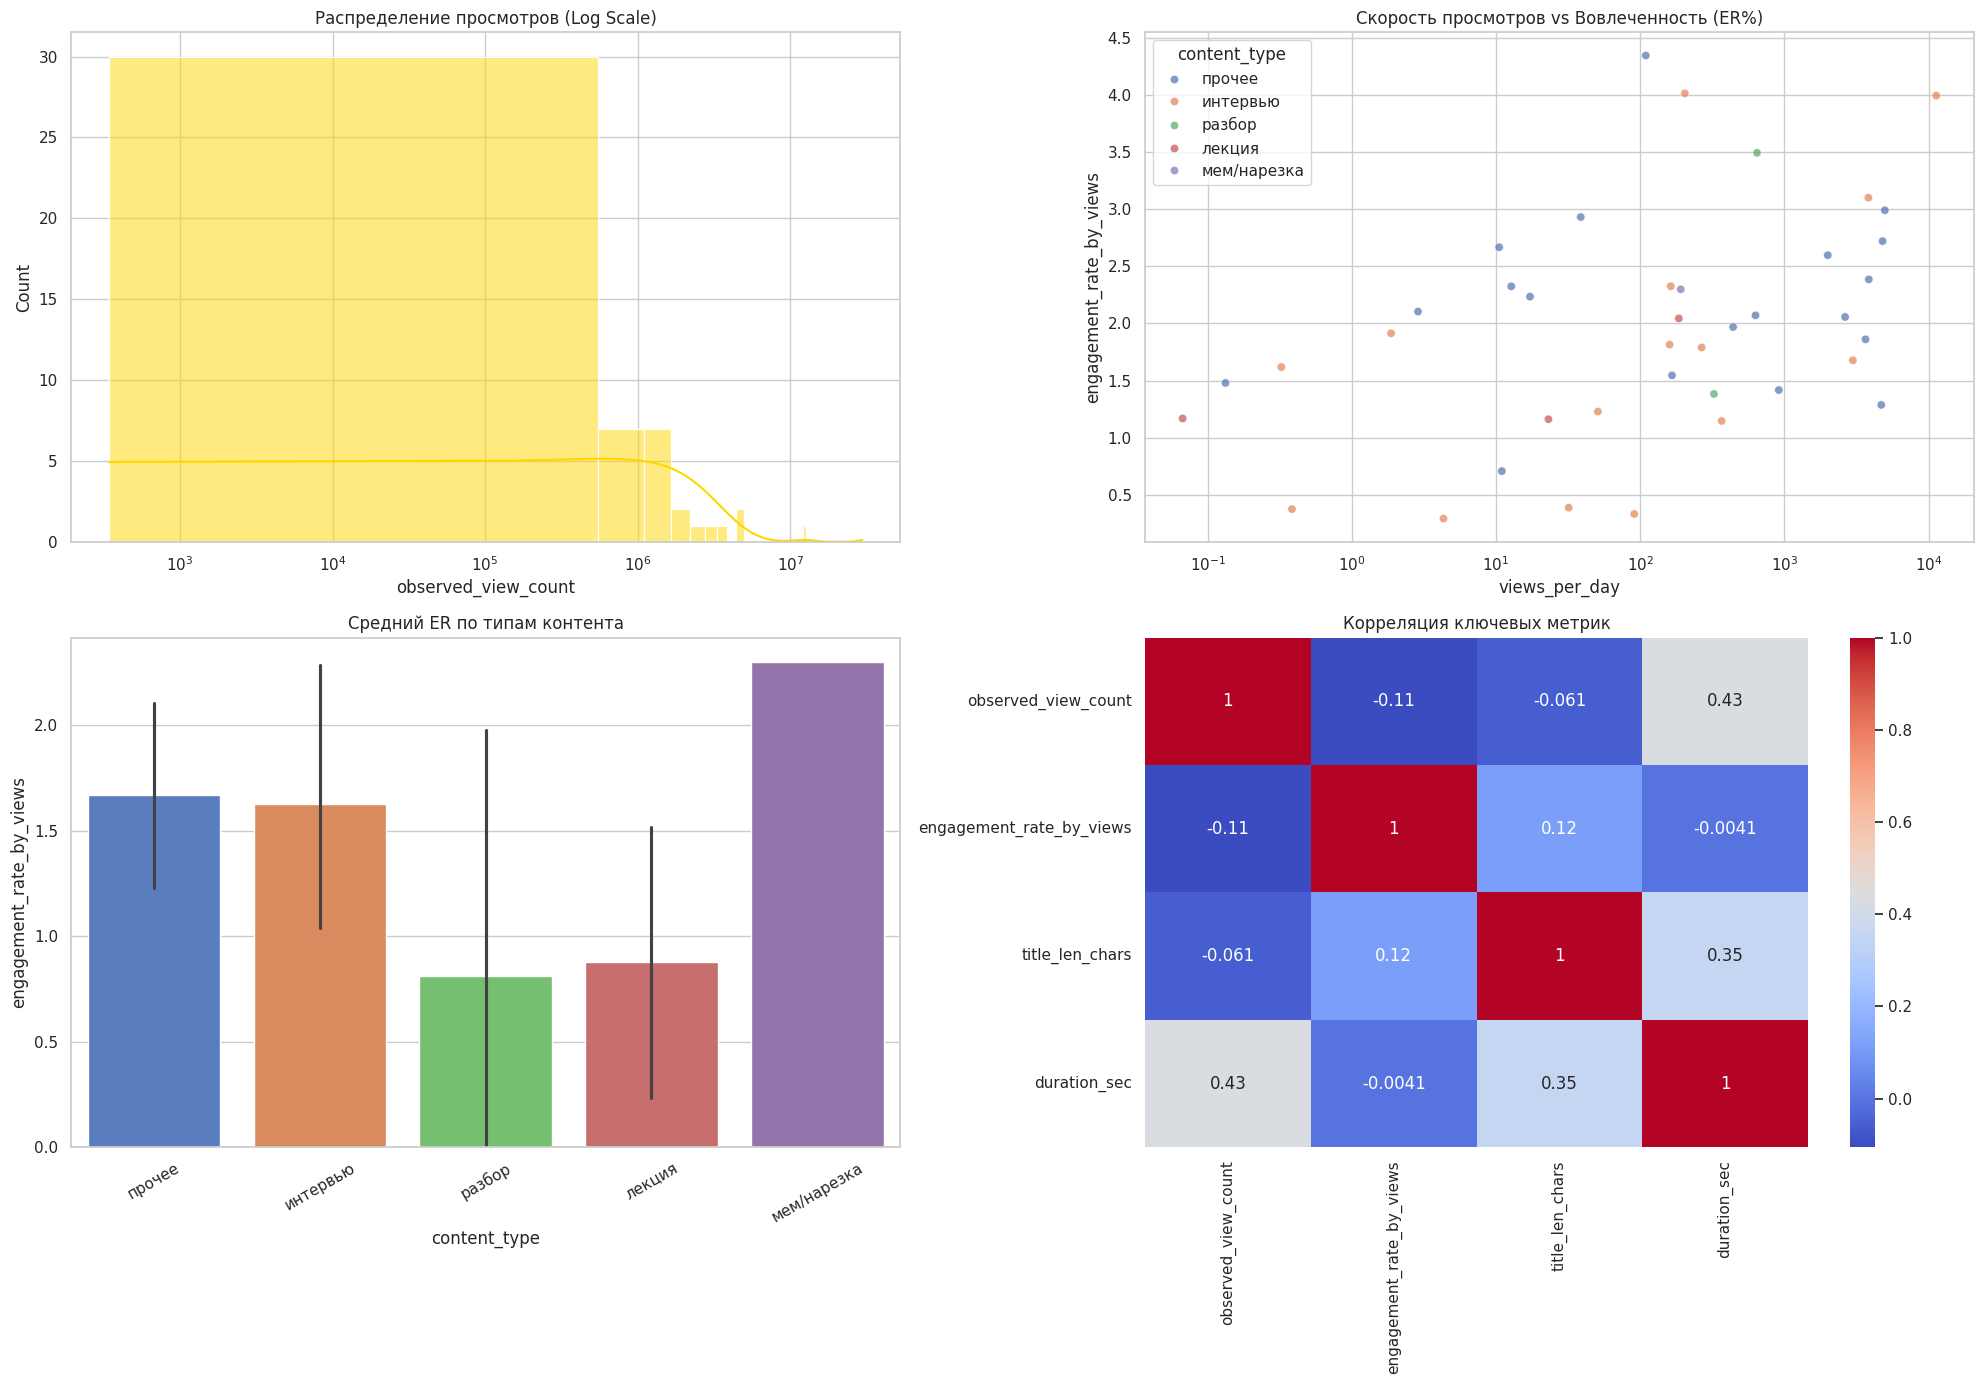

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_master' in globals():
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))

    # 1. Распределение просмотров
    sns.histplot(ax=axes[0, 0], data=df_master, x='observed_view_count', kde=True, color='gold')
    axes[0, 0].set_title('Распределение просмотров (Log Scale)')
    axes[0, 0].set_xscale('log')

    # 2. ER vs Views per Day
    sns.scatterplot(ax=axes[0, 1], data=df_master, x='views_per_day', y='engagement_rate_by_views', hue='content_type', alpha=0.7)
    axes[0, 1].set_title('Скорость просмотров vs Вовлеченность (ER%)')
    axes[0, 1].set_xscale('log')

    # 3. Средний ER по типам контента
    sns.barplot(ax=axes[1, 0], data=df_master, x='content_type', y='engagement_rate_by_views', palette='muted')
    axes[1, 0].set_title('Средний ER по типам контента')
    axes[1, 0].tick_params(axis='x', rotation=30)

    # 4. Корреляции
    corr_cols = ['observed_view_count', 'engagement_rate_by_views', 'title_len_chars', 'duration_sec']
    sns.heatmap(ax=axes[1, 1], data=df_master[[c for c in corr_cols if c in df_master.columns]].corr(), annot=True, cmap='coolwarm')
    axes[1, 1].set_title('Корреляция ключевых метрик')

    plt.tight_layout()
    plt.show()
else:
    print('df_master не найден для визуализации.')

# 📑 Документация проекта: YouTube Media Analytics

## 1. Обзор
Система для автоматизированного сбора и анализа медиа-присутствия в YouTube. Поддерживает инкрементальное обновление данных.

## 2. Логика обновления
- **Upsert**: Данные объединяются с существующими файлами на Google Drive по `video_id` и `comment_id`.
- **Фильтрация**: В мастер-таблицу попадают видео с просмотрами выше заданного порога.

## 3. Ключевые метрики
- **ER (Engagement Rate)**: Отношение взаимодействий к просмотрам.
- **Net Sentiment**: Чистый индекс тональности (от -1 до 1).
- **Content Classification**: Автоматическое определение жанра (интервью, разбор и т.д.).